# Lingala News Topic Classification (MasakhaNEWS)

This single notebook runs the whole project, from the data to the final error analysis.
The Python modules in `src/` hold the reusable code (models, training loops, metrics); this notebook runs the experiments and explains them.

**How to run it:** open it in Google Colab, choose **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**.
It takes about 1.5 hours on a free T4 GPU. Part 6 (fine-tuning pretrained Transformers) needs the GPU and downloads models
from the Hugging Face Hub. Near the end you will be asked for a Hugging Face token if `PUSH_TO_HUB = True`.

| Part | Content |
|---|---|
| 1 | Exploratory data analysis |
| 2 | Baselines: majority class, TF-IDF + Naive Bayes / Logistic Regression / linear SVM |
| 3 | Word2Vec embeddings trained on our articles |
| 4 | BiLSTM / BiGRU with attention |
| 5 | Transformer trained from scratch (control) |
| 6 | Fine-tuning XLM-R and AfroXLMR |
| 7 | Final comparison and error analysis |

**Rules for a fair comparison:** train on `train`, tune on `validation`, use `test` once per final model. Every experiment is
logged in `results/experiment_logs/`, and the test probabilities of every final model are saved in `results/predictions/`.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Your GitHub repository (change it if you use another one)
REPO_URL = "https://github.com/h-mutumwinka/Lingala_News_Classification.git"

if IN_COLAB and not Path("/content/lingala-news-classification").exists():
    !git clone -q {REPO_URL} /content/lingala-news-classification
if IN_COLAB:
    %cd /content/lingala-news-classification
    %pip install -q transformers sentencepiece protobuf huggingface_hub gensim

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

/content/lingala-news-classification
Working directory: /content/lingala-news-classification


# Part 1: Exploratory data analysis

**Goal:** understand the data before modelling. How many articles per topic, how long they are, how big
the vocabulary is, how much French is mixed in, and how consistent the spelling is. Each finding here
motivates a modelling choice later (class weights, character n-grams, accent stripping, truncation length).

In [2]:
import re
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config, data_loading, plots
from src.data_preparation import main as prepare_data
from src.text_processing import strip_accents, tokenise

if not config.TRAIN_FILE.exists():
    prepare_data()

train, validation, test = data_loading.load_all_splits()
everything = pd.concat([train.assign(split="train"), validation.assign(split="validation"), test.assign(split="test")], ignore_index=True)
print("Articles:", len(train), len(validation), len(test), "| total", len(everything))
train.head(3)

Articles: 608 87 175 | total 870


,category,headline,text,content,url
0,health,Bakonzi ya Etats-Unis basengi bakolo basala ba...,Bakonzi ya bokolongono ya Etats-Unis basengi n...,Bakonzi ya Etats-Unis basengi bakolo basala ba...,https://www.voalingala.com/a/bakonzi-ya-etats-...
1,business,FMI elobi kokitisa budget ezali malamu,FMI (Fonds monétaire international) etalisi ko...,FMI elobi kokitisa budget ezali malamu. FMI (F...,https://www.voalingala.com/a/fmi-elobi-kokitis...
2,health,Bituma na Ebola bitelemi na Beni,Botelemeli ya bavandi ya Beni mpe Butembo mpo ...,Bituma na Ebola bitelemi na Beni. Botelemeli y...,https://www.voalingala.com/a/bituma-na-ebola-b...


## 1. Class distribution

split,train,validation,test,share_of_all
category,,,,
politics,350,50,100,0.575
health,135,19,39,0.222
sports,66,10,19,0.109
business,57,8,17,0.094


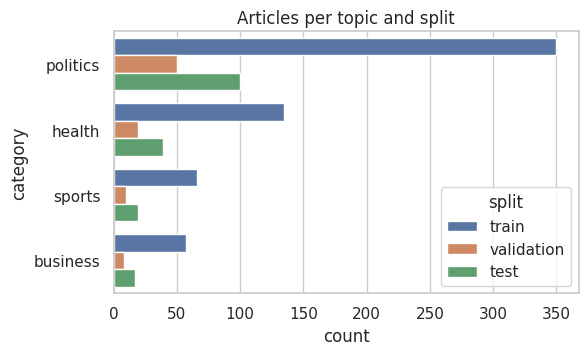

In [3]:
counts = pd.crosstab(everything["category"], everything["split"]).reindex(config.LABELS)[["train", "validation", "test"]]
counts["share_of_all"] = (counts.sum(axis=1) / counts.to_numpy().sum()).round(3)
display(counts)

figure, axis = plt.subplots(figsize=(6, 3.4))
sns.countplot(data=everything, y="category", order=config.LABELS, hue="split", ax=axis)
axis.set_title("Articles per topic and split")
plots.save(figure, "eda", "class_distribution.png");

**Finding:** politics is 57% of the data and business only 9%. A model that always says *politics*
already gets 57% accuracy, which is why **macro-F1** (each class weighted equally) is our main metric
and why we try **class weights**. The validation set has only 8 business and 10 sports articles, so
validation scores are noisy; we add cross-validation for the fast models and several seeds for the neural ones.

## 2. Article length

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
politics,500.0,187.0,73.0,67.0,134.0,177.0,223.0,641.0
health,193.0,176.0,61.0,38.0,135.0,164.0,207.0,348.0
sports,95.0,145.0,56.0,59.0,110.0,136.0,162.0,357.0
business,82.0,185.0,56.0,70.0,148.0,174.0,228.0,336.0


Share of articles with at most 300 words: 0.947


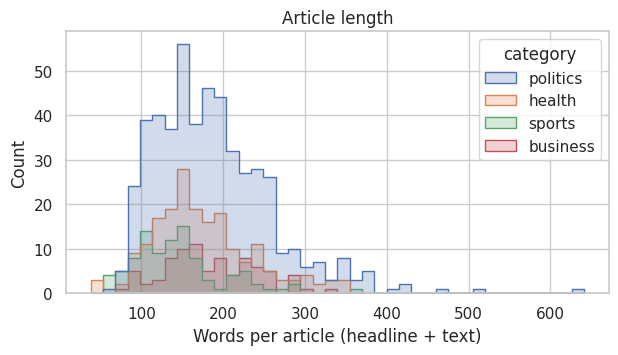

In [4]:
everything["words"] = everything["content"].str.split().str.len()
display(everything.groupby("category")["words"].describe().reindex(config.LABELS).round(0))

figure, axis = plt.subplots(figsize=(7, 3.4))
sns.histplot(data=everything, x="words", hue="category", hue_order=config.LABELS, bins=40, element="step", ax=axis)
axis.set_xlabel("Words per article (headline + text)")
axis.set_title("Article length")
plots.save(figure, "eda", "article_length.png")
print("Share of articles with at most 300 words:", round((everything["words"] <= 300).mean(), 3))

**Finding:** articles are short news items (median about 165 words; the longest is 641). We cap the RNN input at
300 words, which keeps about 95% of articles whole. Transformer subword tokenisers split Lingala words into several
pieces, so we test head-only versus head+tail truncation at 512 subword tokens.

## 3. Vocabulary: size, rare words and unseen words

Training tokens: 110,639  |  distinct words: 10,316
Words seen only once (hapax legomena): 5,485 (53% of the vocabulary)
Share of validation tokens never seen in training: 6.9%
Share of test tokens never seen in training:       6.5%
Most frequent words: ['na', 'ya', 'mpe', 'mpo', 'ba', 'ete', 'ye', 'yango', 'bato', 'm', 'te', 'moko', 'tshisekedi', 'rdc', 'mboka', 'congo', 'baye', 'bango', 'ezali', 'mokonzi', 'nsima', 'président', 'mokambi', 'misala', 'mingi']


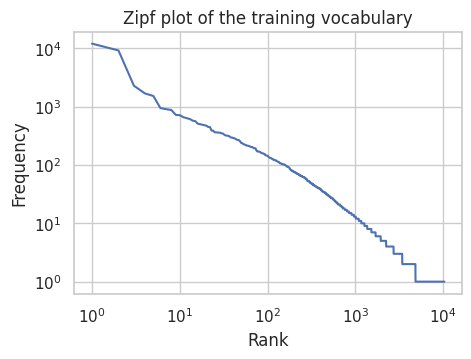

In [5]:
train_tokens = [w for text in train["content"] for w in tokenise(text)]
vocabulary = Counter(train_tokens)
hapax = sum(1 for c in vocabulary.values() if c == 1)
print(f"Training tokens: {len(train_tokens):,}  |  distinct words: {len(vocabulary):,}")
print(f"Words seen only once (hapax legomena): {hapax:,} ({hapax/len(vocabulary):.0%} of the vocabulary)")

def unseen_rate(frame):
    tokens = [w for text in frame["content"] for w in tokenise(text)]
    return np.mean([w not in vocabulary for w in tokens])

print(f"Share of validation tokens never seen in training: {unseen_rate(validation):.1%}")
print(f"Share of test tokens never seen in training:       {unseen_rate(test):.1%}")

ranks = np.arange(1, len(vocabulary) + 1)
frequencies = np.array(sorted(vocabulary.values(), reverse=True))
figure, axis = plt.subplots(figsize=(5, 3.4))
axis.loglog(ranks, frequencies)
axis.set_xlabel("Rank")
axis.set_ylabel("Frequency")
axis.set_title("Zipf plot of the training vocabulary")
plots.save(figure, "eda", "zipf_plot.png")
print("Most frequent words:", [w for w, _ in vocabulary.most_common(25)])

**Finding:** with about 110k training tokens, half the vocabulary appears only once and about 7% of validation and test
tokens were never seen in training. Whole-word models cannot use those words at all. This motivates
**character n-grams** (shared stems and prefixes) and **subword tokenisers** (transformers). The most frequent words are
function words (*ya* 'of', *na* 'with/and', *mpe* 'and', *ete* 'that'); TF-IDF down-weights them automatically.

## 4. Code-mixing with French

In [6]:
# Lingala news from VOA borrows many French words: institutions, titles, sport and economics.
# A rough indicator: words with French-only characters or endings. This undercounts
# (unaccented loans such as "budget" are missed) but shows the trend.
french_pattern = re.compile(r"[éèêëàâçôûùîï]|(?:tion|ment|ique|eur|aire)s?$")

def french_like_share(text):
    tokens = tokenise(text)
    return np.mean([bool(french_pattern.search(t)) for t in tokens]) if tokens else 0

everything["french_like_share"] = everything["content"].apply(french_like_share)
display(everything.groupby("category")["french_like_share"].mean().reindex(config.LABELS).round(3).to_frame("mean share of French-like tokens"))
print("Example:", train.loc[train["category"] == "business", "content"].iloc[0][:300])

,mean share of French-like tokens
category,
politics,0.044
health,0.029
sports,0.048
business,0.044


Example: FMI elobi kokitisa budget ezali malamu. FMI (Fonds monétaire international) etalisi kobanga na yango lolenge bosaleli budget ya RDC ezali kokende mpe ekanisi ete ekozala malamu kokitisa budget. "Lolenge budget esalelami kino kati kati ya sanza ya février ezali kopesa bobangi likolo ya bozito etiyami


**Finding:** even this crude count, which misses unaccented loans such as *budget*, *match* or *club*, finds French in
every topic (3-5% of tokens). Many of the topic words are French (*procès*, *ambassade*, *budget*, *Léopards*, *symptômes*),
often with a Lingala plural prefix attached (*ba stocks*, *ba symptômes*). Many topic signals are in fact French words.
This helps bag-of-words models, and it also means multilingual transformers that know French can transfer knowledge.

## 5. Spelling and accent variation

In [7]:
# Group words that become identical when accents are removed
groups = {}
for word in vocabulary:
    groups.setdefault(strip_accents(word), set()).add(word)
variants = {base: forms for base, forms in groups.items() if len(forms) > 1}
print(f"{len(variants)} words appear in two or more accent spellings in the training data, e.g.:")
for base, forms in list(sorted(variants.items(), key=lambda kv: -sum(vocabulary[f] for f in kv[1])))[:15]:
    print("  ", {form: vocabulary[form] for form in forms})

118 words appear in two or more accent spellings in the training data, e.g.:
   {'ete': 947, 'été': 18}
   {'président': 448, 'president': 43, 'prèsident': 1}
   {'félix': 272, 'felix': 37}
   {'états': 5, 'etats': 204}
   {'democratique': 12, 'démocratique': 194, 'dèmocratique': 1}
   {'état': 24, 'etat': 106}
   {'assemblée': 106, 'assemblee': 3}
   {'general': 14, 'général': 72}
   {'leopards': 11, 'léopards': 69}
   {'sénat': 71, 'senat': 8}
   {'à': 7, 'a': 49}
   {'ministere': 1, 'ministère': 49}
   {'mabele': 43, 'mabélé': 3}
   {'mai': 27, 'maï': 16}
   {'présidence': 40, 'presidence': 2}


**Finding:** the same word appears with and without accents (for example *ete* / *été* 'that'). Lingala tone marks are
optional in everyday writing, and the open vowels ɛ/ɔ are usually written e/o. We therefore test **accent stripping**
as a preprocessing experiment: it merges these spellings, but it can also merge different French words.

## 6. Time period covered

In [8]:
years = Counter(int(y) for text in everything["content"] for y in re.findall(r"\b(20[012]\d)\b", text))
print("Years mentioned in the articles:", dict(sorted(years.items())))
for keyword in ["covid", "ebola", "tshisekedi", "kabila", "trump", "biden"]:
    print(f"{keyword:11s} appears in {everything['content'].str.lower().str.contains(keyword).sum():3d} articles")

Years mentioned in the articles: {2000: 1, 2001: 1, 2002: 9, 2003: 8, 2004: 2, 2005: 4, 2006: 1, 2007: 3, 2008: 1, 2009: 6, 2010: 8, 2011: 4, 2012: 6, 2013: 9, 2014: 10, 2015: 11, 2016: 20, 2017: 23, 2018: 66, 2019: 83, 2020: 94, 2021: 59, 2022: 50, 2023: 32, 2024: 2, 2025: 2, 2026: 1}
covid       appears in 149 articles
ebola       appears in  71 articles
tshisekedi  appears in 294 articles
kabila      appears in 112 articles
trump       appears in  47 articles
biden       appears in  34 articles


## 7. Data quality notes

In [9]:
print("Headlines starting with a lower-case letter (possible scraping cut):",
      everything.loc[everything["headline"].str[0].str.islower(), "headline"].tolist())
print("Shortest articles:")
display(everything.nsmallest(3, "words")[["category", "headline", "words"]])

Headlines starting with a lower-case letter (possible scraping cut): ['avid Blattner abandaki kosamba na TGI/Gombe']
Shortest articles:


,category,headline,words
717,health,COVID-19: Botinda mituna na bino nyonso,38
109,health,COVID-19 na ndako ya pape François,47
735,health,Leader nani azali kosunga bandeko komibatela n...,53


The MasakhaNEWS paper reports a Fleiss' kappa of 0.56 between the two Lingala annotators
(Adelani et al., 2023), which is only moderate agreement (Landis & Koch, 1977). Some labels are therefore debatable, for example court cases about
company directors labelled *business*, or parliamentary decisions about COVID-19 labelled *health*. This sets a ceiling on
achievable accuracy and is important for the error analysis.

## 8. Words that separate the topics

In [10]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

vectoriser = CountVectorizer(token_pattern=r"(?u)[^\W\d_]+|\d+", min_df=3)
counts_matrix = vectoriser.fit_transform(train["content"])
names = vectoriser.get_feature_names_out()
rows = []
for label in config.LABELS:
    in_class = (train["category"] == label).to_numpy()
    scores, _ = chi2(counts_matrix, in_class)
    # chi-squared also rewards words that are unusually RARE in a class; keep only over-represented words
    over_represented = np.asarray(counts_matrix[in_class].mean(axis=0)).ravel() > np.asarray(counts_matrix.mean(axis=0)).ravel()
    scores = np.where(over_represented, scores, 0)
    rows.append({"topic": label, "most distinctive words (chi-squared)": ", ".join(names[np.argsort(scores)[::-1][:12]])})
pd.DataFrame(rows)

,topic,most distinctive words (chi-squared)
0,politics,"maponami, mokonzi, tshisekedi, kabila, lingomb..."
1,health,"ebola, covid, 19, bokono, mangwele, oms, dr, b..."
2,sports,"léopards, club, match, finale, caf, basani, 0,..."
3,business,"bad, gertler, fmi, banque, dan, pétrole, misol..."


**Finding:** sports and health have very clear vocabularies (*Léopards*, *match*, *équipe*; *Ebola*, *coronavirus*, *bokono*
'disease'). Politics and business share names (Tshisekedi, RDC, gouvernement), which predicts that most confusions will be
**business ↔ politics** and **health ↔ politics** (government responses to Ebola/COVID-19).

Years mentioned in the articles are concentrated in 2018–2023, so health news is dominated by Ebola and COVID-19. A model may
learn "Ebola = health" rather than a general notion of health, a **temporal bias** we come back to in the limitations.

# Part 2: Baselines: majority class and TF-IDF bag-of-words models

**Why these baselines?**
* The **majority-class** model is the floor: it predicts the training class shares for every article.
* **TF-IDF + Multinomial Naive Bayes** is the classic text-classification baseline and one of the classical baselines
  in the MasakhaNEWS paper (Adelani et al., 2023), so we can compare with published numbers.
* **TF-IDF + Logistic Regression / linear SVM** are strong linear models that are hard to beat on small datasets
  (Joulin et al., 2017), so any neural model has to justify its extra cost against them.

**Protocol.** Every setting is scored on the validation set *and* with 5-fold cross-validation on the training set
repeated 3 times (15 folds). We choose settings by the **cross-validation mean macro-F1**, because the validation set
has only 87 articles. The test set is used once, at the end, for the chosen models.

In [11]:
import json

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from src import classical_models, config, data_loading, evaluation, plots
from src.cross_validation import cross_validate
from src.experiment_log import log_experiment

MODEL_FAMILY = "bag_of_words"

train, validation, test = data_loading.load_all_splits()
train_ids = data_loading.labels_to_ids(train["category"])
validation_ids = data_loading.labels_to_ids(validation["category"])
test_ids = data_loading.labels_to_ids(test["category"])

In [12]:
results = []

def run(name, settings, notes, text_column=config.TEXT_COLUMN):
    """Fit on train, score on validation, cross-validate on train, log everything."""
    pipeline = classical_models.build_pipeline(settings).fit(train[text_column], train_ids)
    validation_scores = evaluation.compute_scores(validation_ids, pipeline.predict_proba(validation[text_column]))
    cv_scores = cross_validate(lambda: classical_models.build_pipeline(settings), train, text_column)
    all_settings = {**settings, "text_column": text_column}
    log_experiment(MODEL_FAMILY, name, "validation", all_settings, validation_scores, notes)
    log_experiment(MODEL_FAMILY, name, "cv_train", all_settings,
                   {k: v for k, v in cv_scores.items()}, notes)
    results.append({
        "experiment": name,
        "val_macro_f1": validation_scores["macro_f1"],
        "val_weighted_f1": validation_scores["weighted_f1"],
        "cv_macro_f1": cv_scores["macro_f1"],
        "cv_macro_f1_std": cv_scores["macro_f1_std"],
        "settings": all_settings,
    })
    print(f"{name:32s} val macro-F1 {validation_scores['macro_f1']:.3f} | "
          f"CV macro-F1 {cv_scores['macro_f1']:.3f} ± {cv_scores['macro_f1_std']:.3f}")
    return pipeline

## Experiment group A: which classifier?
All use word-unigram TF-IDF features on headline + text.

In [13]:
run("A1_majority", {"classifier": "majority"}, "Floor: predicts class shares")
run("A2_nb_alpha1", {"classifier": "naive_bayes", "features": "word", "alpha": 1.0}, "Default NB smoothing")
run("A3_nb_alpha0.1", {"classifier": "naive_bayes", "features": "word", "alpha": 0.1}, "Less smoothing")
run("A4_complement_nb", {"classifier": "complement_nb", "features": "word", "alpha": 0.3}, "Complement NB for unbalanced classes")
run("A5_logreg", {"classifier": "logistic_regression", "features": "word", "C": 10}, "Logistic regression, no class weights")
run("A6_logreg_balanced", {"classifier": "logistic_regression", "features": "word", "C": 10, "class_weight": True}, "Balanced class weights")
run("A7_svm_balanced", {"classifier": "linear_svm", "features": "word", "C": 1, "class_weight": True}, "Linear SVM, calibrated");

Logged 'A1_majority' (validation) to bag_of_words.csv
Logged 'A1_majority' (cv_train) to bag_of_words.csv
A1_majority                      val macro-F1 0.182 | CV macro-F1 0.183 ± 0.001
Logged 'A2_nb_alpha1' (validation) to bag_of_words.csv
Logged 'A2_nb_alpha1' (cv_train) to bag_of_words.csv
A2_nb_alpha1                     val macro-F1 0.233 | CV macro-F1 0.216 ± 0.020
Logged 'A3_nb_alpha0.1' (validation) to bag_of_words.csv
Logged 'A3_nb_alpha0.1' (cv_train) to bag_of_words.csv
A3_nb_alpha0.1                   val macro-F1 0.753 | CV macro-F1 0.684 ± 0.029
Logged 'A4_complement_nb' (validation) to bag_of_words.csv
Logged 'A4_complement_nb' (cv_train) to bag_of_words.csv
A4_complement_nb                 val macro-F1 0.828 | CV macro-F1 0.746 ± 0.048
Logged 'A5_logreg' (validation) to bag_of_words.csv
Logged 'A5_logreg' (cv_train) to bag_of_words.csv
A5_logreg                        val macro-F1 0.787 | CV macro-F1 0.760 ± 0.035
Logged 'A6_logreg_balanced' (validation) to bag_of_words

**What happened with Naive Bayes at alpha = 1?** TF-IDF values are small (each row is normalised to length 1), so
the word "counts" NB sees are tiny compared with the add-one smoothing. Every word then looks almost equally likely in every
class, and the class prior (57% politics) decides. With alpha = 0.1 the evidence from the words is no longer drowned out.
This is a good reminder that default hyper-parameters are tuned for raw counts on large corpora.

**Class weights** make a mistake on a business article cost about six times as much as one on a politics article, which
forces the model to learn the small classes. This is the biggest single gain in this group.

## Experiment group B: which features?
Logistic regression with balanced class weights, because it is fast, gives probabilities, and its weights can be read.

In [14]:
LOGREG = {"classifier": "logistic_regression", "C": 10, "class_weight": True}
run("B1_word_1-2grams", {**LOGREG, "features": "word", "word_ngrams": (1, 2)}, "Adds word pairs")
run("B2_char_2-5", {**LOGREG, "features": "char", "char_ngrams": (2, 5)}, "Character n-grams inside words")
run("B3_char_3-6", {**LOGREG, "features": "char", "char_ngrams": (3, 6)}, "Longer character n-grams")
run("B4_word+char", {**LOGREG, "features": "word+char"}, "Word 1-2 grams + char 2-5 grams")
run("B5_svm_word+char", {"classifier": "linear_svm", "C": 1, "class_weight": True, "features": "word+char"}, "SVM on word+char");

Logged 'B1_word_1-2grams' (validation) to bag_of_words.csv
Logged 'B1_word_1-2grams' (cv_train) to bag_of_words.csv
B1_word_1-2grams                 val macro-F1 0.866 | CV macro-F1 0.789 ± 0.048
Logged 'B2_char_2-5' (validation) to bag_of_words.csv
Logged 'B2_char_2-5' (cv_train) to bag_of_words.csv
B2_char_2-5                      val macro-F1 0.868 | CV macro-F1 0.852 ± 0.024
Logged 'B3_char_3-6' (validation) to bag_of_words.csv
Logged 'B3_char_3-6' (cv_train) to bag_of_words.csv
B3_char_3-6                      val macro-F1 0.868 | CV macro-F1 0.848 ± 0.029
Logged 'B4_word+char' (validation) to bag_of_words.csv
Logged 'B4_word+char' (cv_train) to bag_of_words.csv
B4_word+char                     val macro-F1 0.881 | CV macro-F1 0.845 ± 0.032
Logged 'B5_svm_word+char' (validation) to bag_of_words.csv
Logged 'B5_svm_word+char' (cv_train) to bag_of_words.csv
B5_svm_word+char                 val macro-F1 0.881 | CV macro-F1 0.855 ± 0.022


## Experiment group C: input text and preprocessing
Using the best feature set so far, we change only the input.

In [15]:
table = pd.DataFrame(results)
best_feature_run = table[table["experiment"].str.startswith(("A", "B"))].sort_values("cv_macro_f1", ascending=False).iloc[0]
BEST = {k: v for k, v in best_feature_run["settings"].items() if k != "text_column"}
print("Best so far by CV:", best_feature_run["experiment"], BEST)

run("C1_headline_only", BEST, "Only the headline", text_column="headline")
run("C2_text_only", BEST, "Only the body text", text_column="text")
run("C3_strip_accents", {**BEST, "strip_accents": True}, "Remove accents: été -> ete, Léopards -> Leopards");

Best so far by CV: B5_svm_word+char {'classifier': 'linear_svm', 'C': 1, 'class_weight': True, 'features': 'word+char'}
Logged 'C1_headline_only' (validation) to bag_of_words.csv
Logged 'C1_headline_only' (cv_train) to bag_of_words.csv
C1_headline_only                 val macro-F1 0.762 | CV macro-F1 0.711 ± 0.039
Logged 'C2_text_only' (validation) to bag_of_words.csv
Logged 'C2_text_only' (cv_train) to bag_of_words.csv
C2_text_only                     val macro-F1 0.881 | CV macro-F1 0.851 ± 0.020
Logged 'C3_strip_accents' (validation) to bag_of_words.csv
Logged 'C3_strip_accents' (cv_train) to bag_of_words.csv
C3_strip_accents                 val macro-F1 0.881 | CV macro-F1 0.858 ± 0.022


## Experiment group D: regularisation strength

In [16]:
if BEST["classifier"] in {"logistic_regression", "linear_svm"}:
    for C in ([1, 100] if BEST["classifier"] == "logistic_regression" else [0.1, 10]):
        run(f"D_C={C}", {**BEST, "C": C}, "Smaller C = stronger regularisation")

Logged 'D_C=0.1' (validation) to bag_of_words.csv
Logged 'D_C=0.1' (cv_train) to bag_of_words.csv
D_C=0.1                          val macro-F1 0.902 | CV macro-F1 0.843 ± 0.029
Logged 'D_C=10' (validation) to bag_of_words.csv
Logged 'D_C=10' (cv_train) to bag_of_words.csv
D_C=10                           val macro-F1 0.881 | CV macro-F1 0.861 ± 0.028


## Summary of all experiments

In [17]:
table = pd.DataFrame(results).drop(columns="settings")
table.sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)

,experiment,val_macro_f1,val_weighted_f1,cv_macro_f1,cv_macro_f1_std
0,D_C=10,0.8811,0.9068,0.8608,0.0276
1,C3_strip_accents,0.8811,0.9068,0.8575,0.0224
2,B5_svm_word+char,0.8811,0.9068,0.8554,0.0219
3,A7_svm_balanced,0.9018,0.9189,0.8537,0.0455
4,B2_char_2-5,0.8675,0.8967,0.8522,0.0235
5,C2_text_only,0.8811,0.9068,0.8509,0.0200
6,B3_char_3-6,0.8675,0.8967,0.8475,0.0285
7,B4_word+char,0.8811,0.9068,0.8453,0.0319
8,D_C=0.1,0.9018,0.9189,0.8429,0.0287
9,A6_logreg_balanced,0.9018,0.9189,0.8398,0.0487


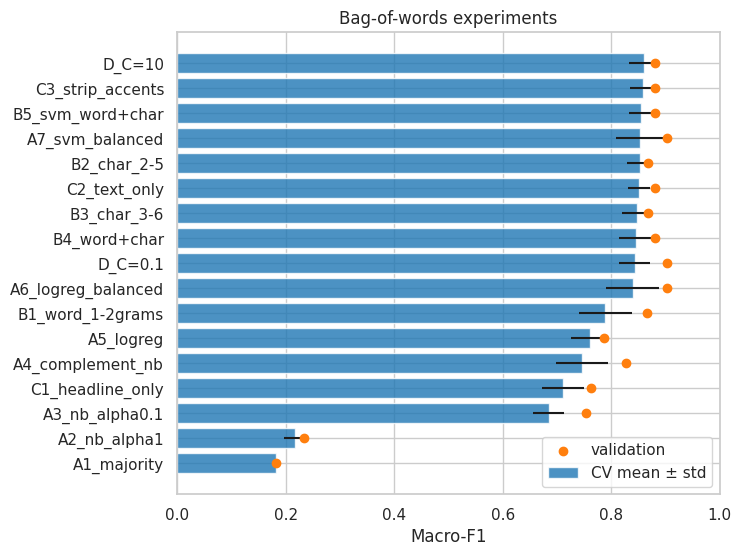

In [18]:
figure, axis = plt.subplots(figsize=(7, 6))
ordered = table.sort_values("cv_macro_f1")
axis.barh(ordered["experiment"], ordered["cv_macro_f1"], xerr=ordered["cv_macro_f1_std"], color="tab:blue", alpha=0.8, label="CV mean ± std")
axis.scatter(ordered["val_macro_f1"], ordered["experiment"], color="tab:orange", zorder=3, label="validation")
axis.set_xlabel("Macro-F1")
axis.set_xlim(0, 1)
axis.legend(loc="lower right")
axis.set_title("Bag-of-words experiments")
plots.save(figure, "bag_of_words", "experiments.png");

## Final models on the test set (used once)
We evaluate three models: the majority floor, the best Naive Bayes (the classical baseline the paper reports), and the best
configuration overall by cross-validation. Each is refit on the training set only (validation is not added) so that every model
family in this project sees exactly the same training data.

In [19]:
full_table = pd.DataFrame(results)
best_overall = full_table.sort_values("cv_macro_f1", ascending=False).iloc[0]
best_nb = full_table[full_table["settings"].apply(lambda s: s.get("classifier") in {"naive_bayes", "complement_nb"})].sort_values("cv_macro_f1", ascending=False).iloc[0]
finalists = {
    "majority": full_table.set_index("experiment").loc["A1_majority", "settings"],
    "tfidf_naive_bayes": best_nb["settings"],
    "tfidf_best": best_overall["settings"],
}
print("Best overall:", best_overall["experiment"], best_overall["settings"])
print("Best NB:", best_nb["experiment"])

final_pipelines = {}
for model_name, settings in finalists.items():
    column = settings.get("text_column", config.TEXT_COLUMN)
    fit_settings = {k: v for k, v in settings.items() if k != "text_column"}
    pipeline = classical_models.build_pipeline(fit_settings).fit(train[column], train_ids)
    probabilities = pipeline.predict_proba(test[column])
    scores = evaluation.compute_scores(test_ids, probabilities)
    low, high = evaluation.bootstrap_confidence_interval(test_ids, probabilities.argmax(1))
    scores["macro_f1_ci_low"], scores["macro_f1_ci_high"] = low, high
    log_experiment(MODEL_FAMILY, f"FINAL_{model_name}", "test", settings, scores, "Final test evaluation")
    evaluation.save_test_predictions(probabilities, model_name)
    final_pipelines[model_name] = pipeline
    print(f"\n=== {model_name}: test macro-F1 {scores['macro_f1']:.3f} (95% CI {low:.3f}-{high:.3f}), weighted-F1 {scores['weighted_f1']:.3f}")
    evaluation.print_classification_report(test_ids, probabilities)

Best overall: D_C=10 {'classifier': 'linear_svm', 'C': 10, 'class_weight': True, 'features': 'word+char', 'text_column': 'content'}
Best NB: A4_complement_nb
Logged 'FINAL_majority' (test) to bag_of_words.csv
Saved test probabilities to /content/lingala-news-classification/results/predictions/majority.csv

=== majority: test macro-F1 0.182 (95% CI 0.165-0.196), weighted-F1 0.416
              precision    recall  f1-score   support

    politics      0.571     1.000     0.727       100
      health      0.000     0.000     0.000        39
      sports      0.000     0.000     0.000        19
    business      0.000     0.000     0.000        17

    accuracy                          0.571       175
   macro avg      0.143     0.250     0.182       175
weighted avg      0.327     0.571     0.416       175

Logged 'FINAL_tfidf_naive_bayes' (test) to bag_of_words.csv
Saved test probabilities to /content/lingala-news-classification/results/predictions/tfidf_naive_bayes.csv

=== tfidf_naive

Saved 25 misclassified test articles to /content/lingala-news-classification/results/misclassified/tfidf_best.csv


,headline,true_label,predicted_label,confidence
26,UE elaki Tshisekedi kobakisa 50 millions $ mpo...,health,politics,0.9229
10,Basali ya société canadienne Banro bakangami n...,business,politics,0.9023
48,Assemblée nationale endimi kobakisi mikolo na ...,health,politics,0.8763
41,Parlement endimi kobakisa mikolo na état d'urg...,health,politics,0.8302
3,Sassou asengi lisungi mpo na Fonds bleu ya bas...,business,politics,0.8213
14,Ouganda na RDC batie manzaka na boyokani mpo n...,business,politics,0.8144
111,"Pompeo akebisi mpo na ""bilaka ya bampa"" ya Chi...",politics,business,0.7877
25,"Kamerhe atiami na ""respiration artificielle"" (...",health,politics,0.7740
60,111 Congolais bakangamaki na France mpe na Bel...,politics,health,0.7534
53,Ruberwa atindami na mbalakaka na Afrique du Su...,health,politics,0.7382


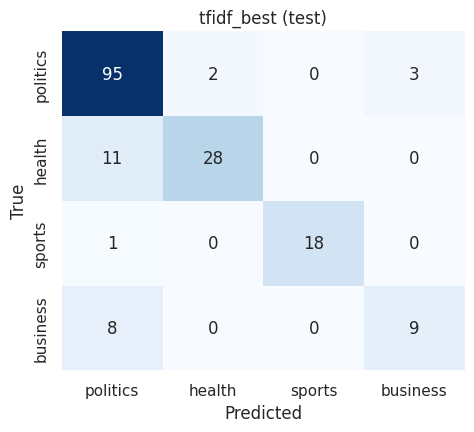

In [20]:
best_probabilities = final_pipelines["tfidf_best"].predict_proba(test[config.TEXT_COLUMN])
plots.plot_confusion_matrix(test_ids, best_probabilities, "tfidf_best", "test")
evaluation.save_misclassified_examples(test, test_ids, best_probabilities, "tfidf_best").head(10)[["headline", "true_label", "predicted_label", "confidence"]]

## Save the model for the web app
The pipeline contains both the TF-IDF vocabulary and the classifier, so the app can call `predict_proba` on raw text.

In [21]:
config.MODELS_DIRECTORY.mkdir(exist_ok=True)
joblib.dump(final_pipelines["tfidf_best"], config.MODELS_DIRECTORY / "tfidf_classifier.joblib")
metadata = {"labels": config.LABELS, "settings": best_overall["settings"], "experiment": best_overall["experiment"]}
(config.MODELS_DIRECTORY / "tfidf_classifier.json").write_text(json.dumps(metadata, indent=2, default=str))
print("Saved", config.MODELS_DIRECTORY / "tfidf_classifier.joblib")

Saved /content/lingala-news-classification/models/tfidf_classifier.joblib


## What did the best linear model learn?

In [22]:
pipeline = final_pipelines["tfidf_best"]
if hasattr(pipeline.named_steps["classifier"], "coef_"):
    top = classical_models.top_features_per_class(pipeline, 20)
    display(pd.DataFrame({label: words for label, words in top.items()}))
else:
    # Calibrated SVM: average the coefficients of the internal SVMs
    import numpy as np
    calibrated = pipeline.named_steps["classifier"].calibrated_classifiers_
    coefficients = np.mean([c.estimator.coef_ for c in calibrated], axis=0)
    names = pipeline.named_steps["tfidf"].get_feature_names_out()
    display(pd.DataFrame({label: [names[i] for i in coefficients[k].argsort()[::-1][:20]] for k, label in enumerate(config.LABELS)}))

,politics,health,sports,business
0,word__maponami,word__covid,word__léopards,word__bad
1,word__mokonzi,word__covid 19,word__club,word__banque
2,word__mampinga,word__19,word__ba léopards,word__misolo
3,word__na bokonzi,word__bokono,word__caf,word__mines
4,word__basoda,word__ebola,word__ndembo,word__pétrole
5,word__bokonzi,word__na covid,word__basani,word__fmi
6,word__mokonzi ya,char__ono,word__finale,word__ya bad
7,char__pona,char__ono,word__mongete,word__mombongo
8,char__nami,char__ cov,char__pards,word__makele
9,word__cour,char__ covi,char__opard,char__banqu


# Part 3: Word2Vec embeddings trained on Lingala news

**Question:** can dense word embeddings learned from only 608 articles (about 110k tokens) replace sparse TF-IDF features?

Word2Vec (Mikolov et al., 2013) learns a vector for each word by predicting its neighbours (skip-gram) or predicting a
word from its neighbours (CBOW). Words used in similar contexts get similar vectors. Here we

1. train Word2Vec on the **training articles only** (no validation/test text, so no leakage),
2. inspect the nearest neighbours to see whether the vectors make sense,
3. represent each article as the **average of its word vectors** and train logistic regression on that,
4. save the best vectors to initialise the BiLSTM / BiGRU in Part 4.

In [23]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

from src import config, data_loading, evaluation, plots
from src.experiment_log import log_experiment
from src.reproducibility import set_seed
from src.word_embeddings import average_document_vectors, nearest_words, train_word2vec

MODEL_FAMILY = "word2vec"
set_seed(config.RANDOM_SEED)

train, validation, test = data_loading.load_all_splits()
train_ids = data_loading.labels_to_ids(train["category"])
validation_ids = data_loading.labels_to_ids(validation["category"])
test_ids = data_loading.labels_to_ids(test["category"])

In [24]:
def classifier():
    return LogisticRegression(C=10, class_weight="balanced", max_iter=5000, random_state=config.RANDOM_SEED)

experiments = {
    "W1_skipgram_100d": {"skip_gram": True, "dimensions": 100, "window": 5, "min_count": 2},
    "W2_cbow_100d": {"skip_gram": False, "dimensions": 100, "window": 5, "min_count": 2},
    "W3_skipgram_300d": {"skip_gram": True, "dimensions": 300, "window": 5, "min_count": 2},
    "W4_skipgram_window10": {"skip_gram": True, "dimensions": 100, "window": 10, "min_count": 2},
    "W5_skipgram_strip_accents": {"skip_gram": True, "dimensions": 100, "window": 5, "min_count": 2, "strip_accents": True},
}

rows, models = [], {}
for name, settings in experiments.items():
    word2vec = train_word2vec(train[config.TEXT_COLUMN], settings)
    accents = settings.get("strip_accents", False)
    x_train = average_document_vectors(train[config.TEXT_COLUMN], word2vec, accents)
    x_validation = average_document_vectors(validation[config.TEXT_COLUMN], word2vec, accents)
    model = classifier().fit(x_train, train_ids)
    scores = evaluation.compute_scores(validation_ids, model.predict_proba(x_validation))
    log_experiment(MODEL_FAMILY, name, "validation", settings, scores, "Averaged Word2Vec + logistic regression")
    rows.append({"experiment": name, "vocabulary": len(word2vec.wv), **{k: scores[k] for k in ["macro_f1", "weighted_f1", "accuracy"]}})
    models[name] = (word2vec, model, settings)

pd.DataFrame(rows).sort_values("macro_f1", ascending=False)

Logged 'W1_skipgram_100d' (validation) to word2vec.csv


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Logged 'W2_cbow_100d' (validation) to word2vec.csv
Logged 'W3_skipgram_300d' (validation) to word2vec.csv
Logged 'W4_skipgram_window10' (validation) to word2vec.csv
Logged 'W5_skipgram_strip_accents' (validation) to word2vec.csv


,experiment,vocabulary,macro_f1,weighted_f1,accuracy
4,W5_skipgram_strip_accents,4790,0.8658,0.9013,0.8966
2,W3_skipgram_300d,4831,0.8501,0.8915,0.8851
0,W1_skipgram_100d,4831,0.8392,0.8854,0.8736
1,W2_cbow_100d,4831,0.8094,0.8362,0.8276
3,W4_skipgram_window10,4831,0.8093,0.8567,0.8506


## Do the vectors make sense? Nearest neighbours

In [25]:
word2vec = models["W1_skipgram_100d"][0]
probe_words = ["ebola", "coronavirus", "léopards", "match", "budget", "banque", "tshisekedi", "mokonzi", "bokono", "mbongo"]
for word, neighbours in nearest_words(word2vec, probe_words).items():
    print(f"{word:12s} -> {', '.join(neighbours)}")

ebola        -> virus, biena, bokono, komonisama, biyibami, mangina
coronavirus  -> yuhan, corovirus, bopanzani, haskell, mobeli, epanzani
léopards     -> balongwe, ecureils, cuper, séniors, seleccion, alongolami
match        -> aller, retour, jss, libungu, zesco, tulu
budget       -> plan, ekanisi, mipesama, ii, loisirs, eleko
banque       -> centrale, privée, bcc, bgif, libulu, comptes
tshisekedi   -> félix, président, tshikedi, felix, belgrade, tshiskedi
mokonzi      -> avanda, moboti, télé, pré, moknzi, mboka
bokono       -> virus, mobeli, bomonani, bosili, azuwami, komonisama
mbongo       -> biyike, mizwi, bozito, ekiti, misosolo, ozwi


**Reading the neighbours.** Frequent topic words get sensible neighbours: *ebola* → *virus*, *bokono* 'disease', *Mangina*
(the town where the 2018 outbreak started); *banque* → *centrale*, *BCC* (Banque Centrale du Congo); *match* → *aller*, *retour*.
The vectors also pull **spelling variants** together: *tshisekedi* → *tshikedi*, *tshiskedi*; *coronavirus* → *corovirus*;
*mokonzi* 'leader' → *moknzi*. This is useful: a bag-of-words model treats each misspelling as an unrelated word.
Rarer words get noisy neighbours (*léopards* → *ecureils*, *seleccion*: other national teams, but also unrelated words), because with
about 110k tokens many words are seen only a handful of times; Word2Vec is normally trained on hundreds of millions of tokens.

## Final evaluation of the best averaged-embedding model on the test set

Logged 'FINAL_W5_skipgram_strip_accents' (test) to word2vec.csv
Saved test probabilities to /content/lingala-news-classification/results/predictions/word2vec_average.csv
W5_skipgram_strip_accents {'accuracy': 0.8743, 'macro_precision': 0.8695, 'macro_recall': 0.8654, 'macro_f1': 0.8598, 'weighted_f1': 0.8747, 'log_loss': 0.3686, 'f1_politics': 0.8976, 'f1_health': 0.8235, 'f1_sports': 1.0, 'f1_business': 0.7179, 'macro_f1_ci_low': 0.7969, 'macro_f1_ci_high': 0.9093}
              precision    recall  f1-score   support

    politics      0.876     0.920     0.898       100
      health      0.966     0.718     0.824        39
      sports      1.000     1.000     1.000        19
    business      0.636     0.824     0.718        17

    accuracy                          0.874       175
   macro avg      0.870     0.865     0.860       175
weighted avg      0.886     0.874     0.875       175



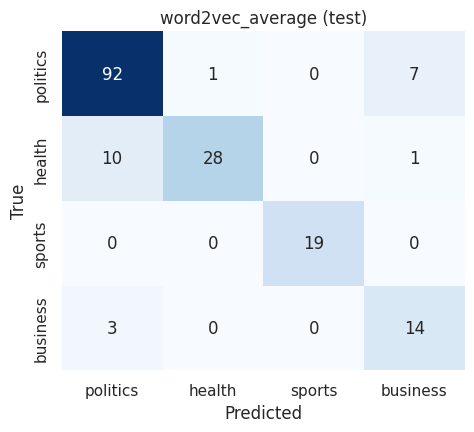

In [26]:
best_name = max(rows, key=lambda r: r["macro_f1"])["experiment"]
word2vec, model, settings = models[best_name]
accents = settings.get("strip_accents", False)
probabilities = model.predict_proba(average_document_vectors(test[config.TEXT_COLUMN], word2vec, accents))
scores = evaluation.compute_scores(test_ids, probabilities)
scores["macro_f1_ci_low"], scores["macro_f1_ci_high"] = evaluation.bootstrap_confidence_interval(test_ids, probabilities.argmax(1))
log_experiment(MODEL_FAMILY, f"FINAL_{best_name}", "test", settings, scores, "Final test evaluation")
evaluation.save_test_predictions(probabilities, "word2vec_average")
print(best_name, scores)
evaluation.print_classification_report(test_ids, probabilities)
plots.plot_confusion_matrix(test_ids, probabilities, "word2vec_average", "test");

**Result.** Averaged skip-gram vectors (with accents stripped) reach a test macro-F1 close to, and here slightly above, the TF-IDF + SVM
baseline from Part 2 (compare the two in Part 7). The validation scores pointed the other way, and the bootstrap intervals
overlap widely, so the honest conclusion is that the two are **comparable** on this test set, not that one is better.

Why can 100 dense numbers per article compete with tens of thousands of sparse TF-IDF features? The embeddings share information between
related words (misspellings, accent variants, words from the same news story), which matters most for the smallest class, **business**:
its recall is higher than with TF-IDF. What averaging loses is word order and the ability to weight one decisive word strongly.

We save the 100-d skip-gram vectors with accents kept (W1), because the RNN vocabulary in Part 4 keeps accents, so the network
can start from these vectors and *fine-tune* them for the task instead of averaging them.

In [27]:
config.MODELS_DIRECTORY.mkdir(exist_ok=True)
models["W1_skipgram_100d"][0].save(str(config.MODELS_DIRECTORY / "word2vec_lingala_100d.model"))
print("Saved word2vec_lingala_100d.model")

Saved word2vec_lingala_100d.model


# Part 4: Recurrent neural networks: BiLSTM and BiGRU with attention

**Questions**
1. Does a sequence model (which reads words in order) beat bag-of-words on this small dataset?
2. Do Word2Vec embeddings trained on our articles help compared with random embeddings? Should they be frozen or fine-tuned?
3. LSTM or GRU? Attention pooling or the last hidden state?
4. Do class weights help, as they did for logistic regression?

**Architecture** (see `src/rnn_models.py`):
`words → embedding (100-d) → bidirectional LSTM/GRU (2 × 128) → attention pooling → dropout → linear → softmax over 4 topics`.

Training: Adam (lr 1e-3), batch size 16, cross-entropy loss (optionally class-weighted), gradient clipping at 1.0, up to
25 epochs with **early stopping** when validation macro-F1 has not improved for 6 epochs; we keep the best epoch's weights.
Input is capped at 300 words (95% of articles fit whole).

Each experiment changes **one thing** relative to the reference run R2. Exploration uses one seed (42); the final configuration
is retrained with 3 seeds and we report the mean and standard deviation.

In [28]:
import time

import pandas as pd
import torch
from gensim.models import Word2Vec

from src import config, data_loading, evaluation, plots, rnn_models
from src.experiment_log import log_experiment
from src.word_embeddings import embedding_matrix_for_vocabulary

MODEL_FAMILY = "rnn"
torch.set_num_threads(max(1, torch.get_num_threads()))

train, validation, test = data_loading.load_all_splits()
validation_ids = data_loading.labels_to_ids(validation["category"])
test_ids = data_loading.labels_to_ids(test["category"])

word2vec = Word2Vec.load(str(config.MODELS_DIRECTORY / "word2vec_lingala_100d.model"))

def word2vec_embeddings(vocabulary, seed=config.RANDOM_SEED):
    matrix, coverage = embedding_matrix_for_vocabulary(vocabulary, word2vec, seed)
    print(f"  Word2Vec covers {coverage:.0%} of the RNN vocabulary")
    return matrix

In [29]:
REFERENCE = {
    "cell": "lstm", "pooling": "attention", "embeddings": "word2vec", "freeze_embeddings": False,
    "embedding_dimensions": 100, "hidden_size": 128, "dropout": 0.3, "embedding_dropout": 0.2,
    "learning_rate": 1e-3, "batch_size": 16, "epochs": 25, "patience": 6,
    "min_count": 2, "max_length": 300, "class_weight": True,
}

results, histories = [], {}

def run(name, changes, notes, seed=config.RANDOM_SEED):
    settings = {**REFERENCE, **changes}
    started = time.time()
    embeddings_fn = word2vec_embeddings if settings["embeddings"] == "word2vec" else None
    model, vocabulary, history = rnn_models.train_recurrent_model(settings, train, validation, seed, embeddings_fn)
    probabilities = rnn_models.predict_dataframe(model, vocabulary, validation, settings)
    scores = evaluation.compute_scores(validation_ids, probabilities)
    scores["best_epoch"] = history["best_epoch"]
    log_experiment(MODEL_FAMILY, name, "validation", {**settings, "seed": seed}, scores, notes)
    results.append({"experiment": name, "change": notes, **{k: scores[k] for k in ["macro_f1", "weighted_f1", "log_loss"]},
                    "best_epoch": history["best_epoch"], "minutes": round((time.time() - started) / 60, 1)})
    histories[name] = history
    print(f"{name}: validation macro-F1 {scores['macro_f1']:.3f} (best epoch {history['best_epoch']}, {results[-1]['minutes']} min)")
    return model, vocabulary, settings

In [30]:
run("R1_bilstm_random_embeddings", {"embeddings": "random"}, "Random embeddings instead of Word2Vec")
run("R2_bilstm_word2vec_finetuned", {}, "Reference: Word2Vec init, fine-tuned")
run("R3_bilstm_word2vec_frozen", {"freeze_embeddings": True}, "Word2Vec frozen (not updated)")
run("R4_bilstm_last_state", {"pooling": "last"}, "Last hidden state instead of attention")
run("R5_bigru_attention", {"cell": "gru"}, "GRU instead of LSTM")
run("R6_bilstm_no_class_weights", {"class_weight": False}, "Unweighted cross-entropy");

Logged 'R1_bilstm_random_embeddings' (validation) to rnn.csv
R1_bilstm_random_embeddings: validation macro-F1 0.853 (best epoch 24, 0.5 min)
  Word2Vec covers 100% of the RNN vocabulary
Logged 'R2_bilstm_word2vec_finetuned' (validation) to rnn.csv
R2_bilstm_word2vec_finetuned: validation macro-F1 0.888 (best epoch 12, 0.3 min)
  Word2Vec covers 100% of the RNN vocabulary
Logged 'R3_bilstm_word2vec_frozen' (validation) to rnn.csv
R3_bilstm_word2vec_frozen: validation macro-F1 0.900 (best epoch 12, 0.3 min)
  Word2Vec covers 100% of the RNN vocabulary
Logged 'R4_bilstm_last_state' (validation) to rnn.csv
R4_bilstm_last_state: validation macro-F1 0.895 (best epoch 9, 0.2 min)
  Word2Vec covers 100% of the RNN vocabulary
Logged 'R5_bigru_attention' (validation) to rnn.csv
R5_bigru_attention: validation macro-F1 0.874 (best epoch 3, 0.1 min)
  Word2Vec covers 100% of the RNN vocabulary
Logged 'R6_bilstm_no_class_weights' (validation) to rnn.csv
R6_bilstm_no_class_weights: validation macro-F

In [31]:
summary = pd.DataFrame(results)
summary

,experiment,change,macro_f1,weighted_f1,log_loss,best_epoch,minutes
0,R1_bilstm_random_embeddings,Random embeddings instead of Word2Vec,0.8530,0.9093,0.6833,24,0.5
1,R2_bilstm_word2vec_finetuned,"Reference: Word2Vec init, fine-tuned",0.8880,0.9272,0.3704,12,0.3
2,R3_bilstm_word2vec_frozen,Word2Vec frozen (not updated),0.9002,0.9197,0.3345,12,0.3
3,R4_bilstm_last_state,Last hidden state instead of attention,0.8946,0.9311,0.3248,9,0.2
4,R5_bigru_attention,GRU instead of LSTM,0.8739,0.9026,0.5510,3,0.1
5,R6_bilstm_no_class_weights,Unweighted cross-entropy,0.9052,0.9303,0.2120,17,0.4


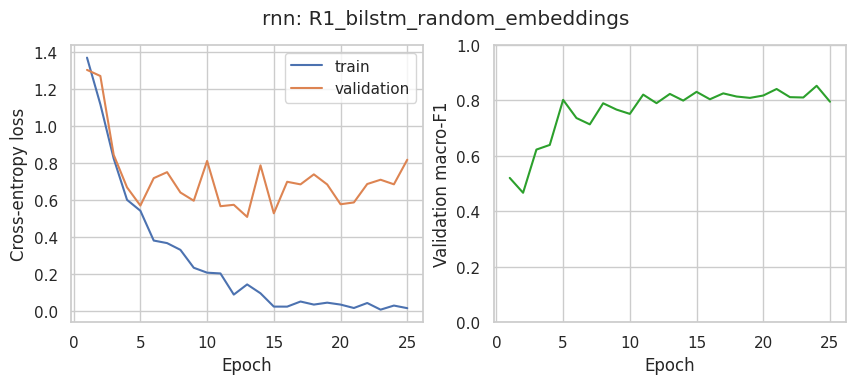

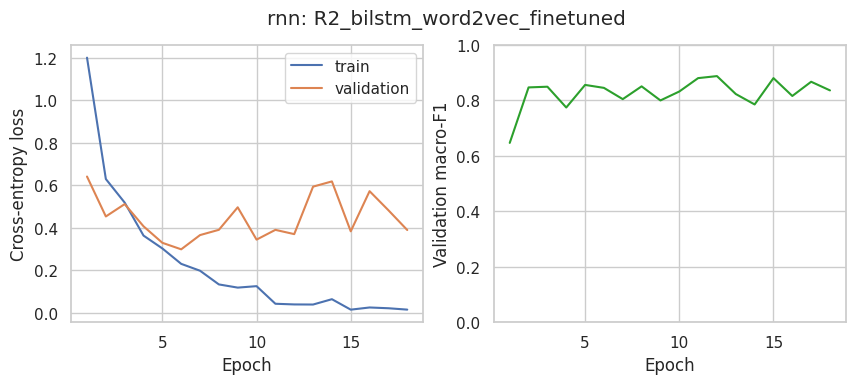

In [32]:
for name in ["R1_bilstm_random_embeddings", "R2_bilstm_word2vec_finetuned"]:
    plots.plot_learning_curves(histories[name], "rnn", name)

**How to read the learning curves.** Training loss keeps falling while validation loss flattens or rises after a few
epochs: the network starts memorising the 608 training articles. Early stopping keeps the epoch with the best validation
macro-F1. The validation macro-F1 curve is jumpy because one article out of 8 business or 10 sports articles moves it by
several points; this is why the final model is run with three seeds.

## Final configuration: three seeds, evaluated on the test set

Final configuration: R6_bilstm_no_class_weights {'class_weight': False}
  Word2Vec covers 100% of the RNN vocabulary
seed 42: test macro-F1 0.886
  Word2Vec covers 100% of the RNN vocabulary
seed 7: test macro-F1 0.855
  Word2Vec covers 100% of the RNN vocabulary
seed 2026: test macro-F1 0.835
Logged 'FINAL_R6_bilstm_no_class_weights' (test) to rnn.csv
Saved test probabilities to /content/lingala-news-classification/results/predictions/rnn.csv
Test macro-F1 0.859 ± 0.026 over 3 seeds
              precision    recall  f1-score   support

    politics      0.905     0.950     0.927       100
      health      0.895     0.872     0.883        39
      sports      1.000     1.000     1.000        19
    business      0.846     0.647     0.733        17

    accuracy                          0.909       175
   macro avg      0.911     0.867     0.886       175
weighted avg      0.907     0.909     0.906       175



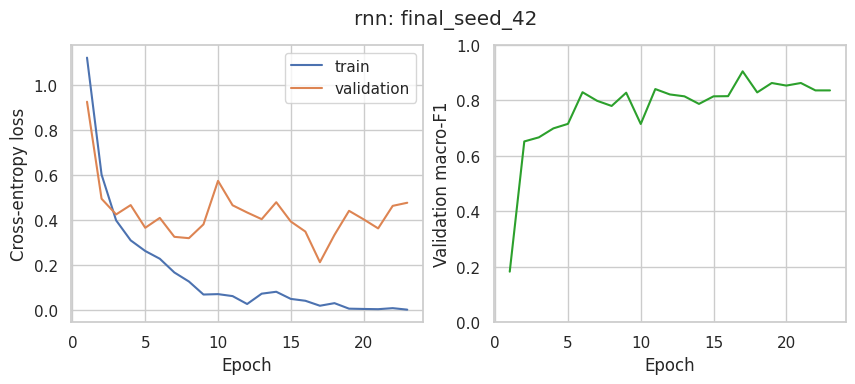

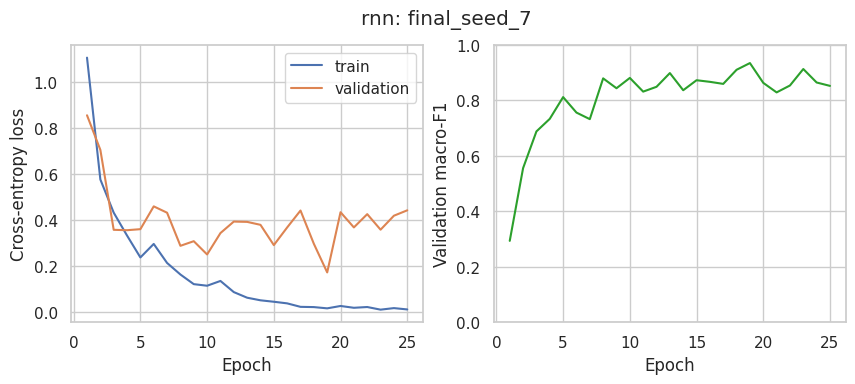

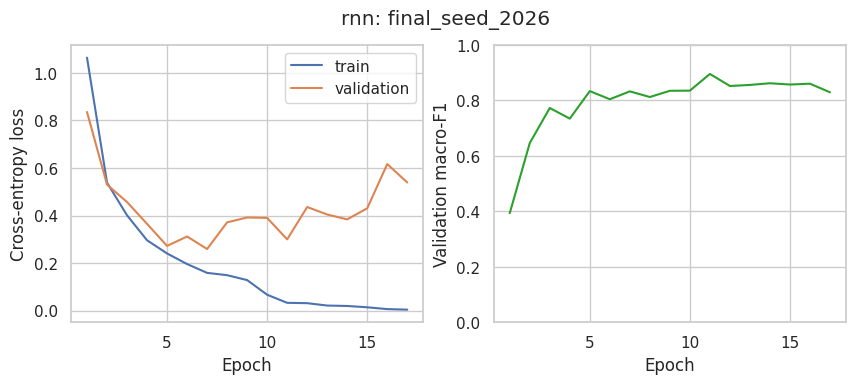

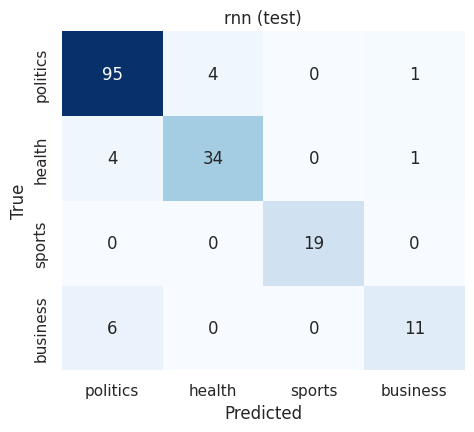

In [33]:
best = summary.sort_values(["macro_f1", "log_loss"], ascending=[False, True]).iloc[0]["experiment"]
changes = {
    "R1_bilstm_random_embeddings": {"embeddings": "random"},
    "R2_bilstm_word2vec_finetuned": {},
    "R3_bilstm_word2vec_frozen": {"freeze_embeddings": True},
    "R4_bilstm_last_state": {"pooling": "last"},
    "R5_bigru_attention": {"cell": "gru"},
    "R6_bilstm_no_class_weights": {"class_weight": False},
}[best]
print("Final configuration:", best, changes)

seed_scores, seed_models = [], {}
for seed in config.FINAL_RUN_SEEDS:
    settings = {**REFERENCE, **changes}
    embeddings_fn = (lambda v, s=seed: word2vec_embeddings(v, s)) if settings["embeddings"] == "word2vec" else None
    model, vocabulary, history = rnn_models.train_recurrent_model(settings, train, validation, seed, embeddings_fn)
    probabilities = rnn_models.predict_dataframe(model, vocabulary, test, settings)
    scores = evaluation.compute_scores(test_ids, probabilities)
    seed_scores.append(scores)
    seed_models[seed] = (model, vocabulary, probabilities)
    plots.plot_learning_curves(history, "rnn", f"final_seed_{seed}")
    print(f"seed {seed}: test macro-F1 {scores['macro_f1']:.3f}")

summary_scores = evaluation.summarise_runs(seed_scores)
first_seed = config.FINAL_RUN_SEEDS[0]
low, high = evaluation.bootstrap_confidence_interval(test_ids, seed_models[first_seed][2].argmax(1))
summary_scores["macro_f1_ci_low"], summary_scores["macro_f1_ci_high"] = low, high
log_experiment(MODEL_FAMILY, f"FINAL_{best}", "test", {**REFERENCE, **changes, "seeds": config.FINAL_RUN_SEEDS},
               summary_scores, "Mean and std over 3 seeds; CI from seed 42")
evaluation.save_test_predictions(seed_models[first_seed][2], "rnn")
print(f"Test macro-F1 {summary_scores['macro_f1']:.3f} ± {summary_scores['macro_f1_std']:.3f} over {len(seed_scores)} seeds")
evaluation.print_classification_report(test_ids, seed_models[first_seed][2])
plots.plot_confusion_matrix(test_ids, seed_models[first_seed][2], "rnn", "test");

## What does the attention look at?
We use the attention model (the final model if it uses attention, otherwise the reference run R2). For a few test articles we list the words with the highest attention weight. If attention is useful, the top words should be
topic words, not function words. (Attention weights are a hint about what the model used, not a full explanation; Jain & Wallace, 2019.)

In [34]:
final_settings = {**REFERENCE, **changes}
if final_settings["pooling"] == "attention":
    model, vocabulary, probabilities = seed_models[first_seed]
    attention_settings = final_settings
else:
    # The final model uses the last hidden state, so we inspect the attention model R2 instead
    attention_settings = REFERENCE
    model, vocabulary, _ = rnn_models.train_recurrent_model(REFERENCE, train, validation, first_seed, word2vec_embeddings)
    probabilities = rnn_models.predict_dataframe(model, vocabulary, test, REFERENCE)
if True:
    table = evaluation.build_prediction_table(test, test_ids, probabilities)
    examples = pd.concat([table[table["correct"]].groupby("true_label").head(1),
                          table[~table["correct"]].sort_values("confidence", ascending=False).head(4)])
    rows = []
    for index, row in examples.iterrows():
        top_words = rnn_models.attention_for_text(model, vocabulary, row["content"], attention_settings, top=8)
        rows.append({"headline": row["headline"][:70], "true": row["true_label"], "predicted": row["predicted_label"],
                     "top attention words": ", ".join(w for w, _ in top_words)})
    attention_table = pd.DataFrame(rows)
    attention_table.to_csv(config.RESULTS_DIRECTORY / "figures" / "rnn" / "attention_examples.csv", index=False)
    display(attention_table)

,headline,true,predicted,top attention words
0,avid Blattner abandaki kosamba na TGI/Gombe,business,business,"association, congolaise, pour, acaj, accès, l,..."
1,Session extraordinaire ya Assemblée provincial...,health,health,"covid, covid, 19, covid, 19, bokono, na, 19"
2,Biden aboyi bondongwani na Russie na Ukraine b...,politics,politics,"biden, joe, e, mondiale, alobi, biden, 3, ukraine"
3,"Général Amisi ""Tango Four"" alongwe na bokambi ...",sports,sports,"club, v, s, a, club, bokambami, alongwe, ya"
4,Bozongisami ya bitiki ya nzoto ya Lumumba boti...,politics,health,"covid, nzoto, 19, lumumba, bozongisami, nkondo..."
5,Basali ya société canadienne Banro bakangami n...,business,politics,"minduki, basimba, société, basali, basali, bak..."
6,Etat d'urgence na Congo-Brazzaville mpo na mpela,health,politics,"bakonzi, brazzaville, congo, mpela, mpo, etat,..."
7,"Rwanda elobi ebomi 19 ""terroristes"" na ndelo n...",politics,health,"19, ebomi, 19, elobi, rwanda, terroristes, 19,..."


# Part 5: A Transformer trained from scratch (control experiment)

**Question:** is the Transformer *architecture* enough, or does the benefit come from *pre-training* on large text corpora?

We train a small BERT-style encoder (Devlin et al., 2019) whose weights all start random and which sees only our 608
training articles. It uses its own WordPiece tokeniser learned from the same articles. If it does much worse than the
fine-tuned pretrained models in Part 6, the gain there comes from what was learned during pre-training, not from
self-attention itself. This runs on a CPU in a few minutes.

In [35]:
import pandas as pd
import torch

from src import config, data_loading, evaluation, plots, scratch_transformer, transformer_training
from src.experiment_log import log_experiment

MODEL_FAMILY = "transformer_scratch"
train, validation, test = data_loading.load_all_splits()
validation_ids = data_loading.labels_to_ids(validation["category"])
test_ids = data_loading.labels_to_ids(test["category"])

tokenizer = scratch_transformer.train_wordpiece_tokeniser(
    train[config.TEXT_COLUMN], vocabulary_size=8000, directory=config.MODELS_DIRECTORY / "scratch_tokeniser")
print("Vocabulary size:", tokenizer.vocab_size)
print("Subword statistics on train:", transformer_training.subword_statistics(tokenizer, train[config.TEXT_COLUMN]))
print(tokenizer.tokenize(train[config.TEXT_COLUMN].iloc[1])[:30])

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (673 > 512). Running this sequence through the model will result in indexing errors


Vocabulary size: 8000
Subword statistics on train: {'tokens_per_word': 1.264, 'share_truncated_at_512': 0.008}
['fmi', 'elobi', 'kokitisa', 'budget', 'ezali', 'malamu', '.', 'fmi', '(', 'fonds', 'monétaire', 'international', ')', 'etalisi', 'kobanga', 'na', 'yango', 'lolenge', 'bosaleli', 'budget', 'ya', 'rdc', 'ezali', 'kokende', 'mpe', 'ekanisi', 'ete', 'ekozala', 'malamu', 'kokitisa']


In [36]:
BASE = {"hidden_size": 128, "layers": 2, "heads": 4, "max_tokens": 256, "strategy": "head",
        "learning_rate": 5e-4, "batch_size": 16, "epochs": 40, "patience": 8, "class_weight": True,
        "seed": config.RANDOM_SEED}
results, histories = [], {}

def run(name, changes, notes, seed=config.RANDOM_SEED, evaluate_on=None):
    settings = {**BASE, **changes, "seed": seed}
    model = scratch_transformer.build_scratch_model(tokenizer, settings)
    model, _, history = transformer_training.run_experiment(settings, train, validation, model=model, tokenizer=tokenizer)
    probabilities = transformer_training.predict_probabilities(model, tokenizer, validation, settings)
    scores = evaluation.compute_scores(validation_ids, probabilities)
    scores["parameters"] = scratch_transformer.count_parameters(model)
    log_experiment(MODEL_FAMILY, name, "validation", settings, scores, notes)
    results.append({"experiment": name, "change": notes, "parameters": scores["parameters"],
                    "macro_f1": scores["macro_f1"], "weighted_f1": scores["weighted_f1"], "best_epoch": history["best_epoch"]})
    histories[name] = history
    return model, settings

In [37]:
torch.set_num_threads(max(1, torch.get_num_threads()))
run("T1_2layers_128d", {}, "2 layers, hidden 128, 256 tokens")
run("T2_4layers_256d", {"layers": 4, "hidden_size": 256, "learning_rate": 3e-4}, "Bigger: 4 layers, hidden 256")
run("T3_2layers_512tokens", {"max_tokens": 512}, "Longer input: 512 tokens")
summary = pd.DataFrame(results)
summary

Epoch 1: train loss 1.3874, validation loss 1.3679, macro-F1 0.1825
Epoch 2: train loss 1.3915, validation loss 1.3791, macro-F1 0.0515
Epoch 3: train loss 1.3897, validation loss 1.3598, macro-F1 0.2172
Epoch 4: train loss 1.0454, validation loss 0.7775, macro-F1 0.6844
Epoch 5: train loss 0.5340, validation loss 0.5337, macro-F1 0.7831
Epoch 6: train loss 0.2402, validation loss 0.4286, macro-F1 0.8460
Epoch 7: train loss 0.0727, validation loss 0.5187, macro-F1 0.7827
Epoch 8: train loss 0.0392, validation loss 0.5820, macro-F1 0.8018
Epoch 9: train loss 0.0154, validation loss 0.5720, macro-F1 0.8166
Epoch 10: train loss 0.0079, validation loss 0.5734, macro-F1 0.8084
Epoch 11: train loss 0.0059, validation loss 0.5702, macro-F1 0.7914
Epoch 12: train loss 0.0048, validation loss 0.5807, macro-F1 0.8111
Epoch 13: train loss 0.0039, validation loss 0.6008, macro-F1 0.8111
Epoch 14: train loss 0.0033, validation loss 0.6306, macro-F1 0.8030
Early stopping
Logged 'T1_2layers_128d' (va

,experiment,change,parameters,macro_f1,weighted_f1,best_epoch
0,T1_2layers_128d,"2 layers, hidden 128, 256 tokens",1470852,0.8460,0.8721,6
1,T2_4layers_256d,"Bigger: 4 layers, hidden 256",5340420,0.8460,0.8846,9
2,T3_2layers_512tokens,Longer input: 512 tokens,1503620,0.8262,0.8731,10


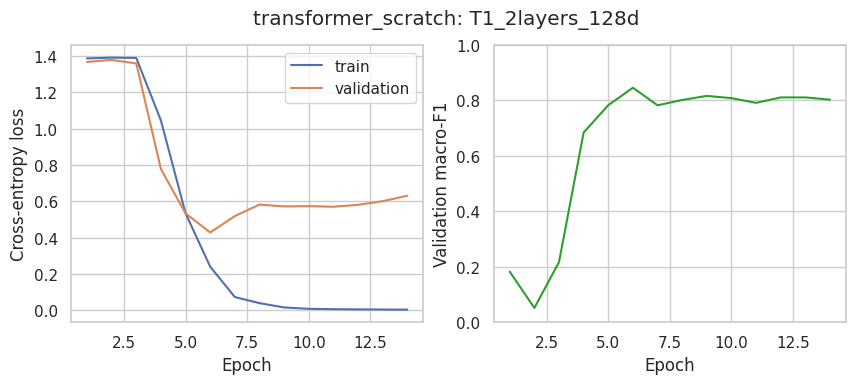

In [38]:
plots.plot_learning_curves(histories["T1_2layers_128d"], "transformer_scratch", "T1_2layers_128d");

## Final: best configuration, three seeds, test set

In [39]:
best = summary.sort_values("macro_f1", ascending=False).iloc[0]["experiment"]
changes = {"T1_2layers_128d": {}, "T2_4layers_256d": {"layers": 4, "hidden_size": 256, "learning_rate": 3e-4},
           "T3_2layers_512tokens": {"max_tokens": 512}}[best]
seed_scores, first_probabilities = [], None
for seed in config.FINAL_RUN_SEEDS:
    settings = {**BASE, **changes, "seed": seed}
    model = scratch_transformer.build_scratch_model(tokenizer, settings)
    model, _, _ = transformer_training.run_experiment(settings, train, validation, model=model, tokenizer=tokenizer)
    probabilities = transformer_training.predict_probabilities(model, tokenizer, test, settings)
    seed_scores.append(evaluation.compute_scores(test_ids, probabilities))
    first_probabilities = probabilities if first_probabilities is None else first_probabilities

summary_scores = evaluation.summarise_runs(seed_scores)
summary_scores["macro_f1_ci_low"], summary_scores["macro_f1_ci_high"] = evaluation.bootstrap_confidence_interval(test_ids, first_probabilities.argmax(1))
log_experiment(MODEL_FAMILY, f"FINAL_{best}", "test", {**BASE, **changes, "seeds": config.FINAL_RUN_SEEDS}, summary_scores, "Mean/std over 3 seeds")
evaluation.save_test_predictions(first_probabilities, "transformer_scratch")
print(f"{best}: test macro-F1 {summary_scores['macro_f1']:.3f} ± {summary_scores['macro_f1_std']:.3f}")
evaluation.print_classification_report(test_ids, first_probabilities)

Epoch 1: train loss 1.3872, validation loss 1.3620, macro-F1 0.1825
Epoch 2: train loss 1.3895, validation loss 1.3819, macro-F1 0.0515
Epoch 3: train loss 1.3869, validation loss 1.3641, macro-F1 0.2527
Epoch 4: train loss 0.9972, validation loss 0.7304, macro-F1 0.6717
Epoch 5: train loss 0.5331, validation loss 0.6105, macro-F1 0.7087
Epoch 6: train loss 0.4264, validation loss 0.5666, macro-F1 0.7212
Epoch 7: train loss 0.1717, validation loss 0.5428, macro-F1 0.8191
Epoch 8: train loss 0.0454, validation loss 0.6259, macro-F1 0.8786
Epoch 9: train loss 0.0390, validation loss 0.8736, macro-F1 0.8017
Epoch 10: train loss 0.0138, validation loss 0.8277, macro-F1 0.8287
Epoch 11: train loss 0.0094, validation loss 1.0287, macro-F1 0.7729
Epoch 12: train loss 0.0074, validation loss 0.9200, macro-F1 0.8169
Epoch 13: train loss 0.0056, validation loss 0.9924, macro-F1 0.8333
Epoch 14: train loss 0.0048, validation loss 1.0371, macro-F1 0.8333
Epoch 15: train loss 0.0041, validation los

**Interpretation.** Self-attention has many parameters and no built-in knowledge of language; with 608 articles it has to
learn word meanings, Lingala morphology and the topics all at once. Compare this score with the bag-of-words models (Part 2)
and the fine-tuned pretrained models (Part 6): the architecture alone does not explain the gains of pretrained Transformers.

# Part 6: Fine-tuning pretrained multilingual Transformers

This part needs the GPU (about 45-60 minutes on a T4).

**Questions**
1. Does a pretrained Transformer beat the TF-IDF baseline on 608 Lingala articles?
2. Does it matter whether the model was adapted to African languages? We compare
   * `xlm-roberta-base` (Conneau et al., 2020): 100 languages from CommonCrawl, mostly high-resource; includes French and Swahili.
   * `Davlan/afro-xlmr-base` (Alabi et al., 2022): XLM-R further pre-trained (MAFT) on 17 African languages plus English, French and Arabic.
     **Lingala is not one of the 17**, so any gain over XLM-R comes from related Bantu languages (Swahili, Kinyarwanda, Kirundi, …) and French.
   * `Davlan/afro-xlmr-base-76L` (optional): a later MAFT model on 76 languages. Check its model card for Lingala (`lin`) before
     claiming that it saw Lingala in pre-training.
3. For the best model: head-only vs head+tail truncation, and class weights on/off.

**Fine-tuning recipe** (Devlin et al., 2019; Sun et al., 2019): AdamW, learning rate 2e-5, 10% linear warm-up then linear decay,
weight decay 0.01, batch size 16, up to 10 epochs, early stopping (patience 3) on validation macro-F1, gradient clipping 1.0,
mixed precision (fp16) on the GPU. The input is `headline. text`, up to 512 subword tokens.

In [40]:
import json
import shutil

import pandas as pd
import torch
from transformers import AutoTokenizer

from src import config, data_loading, evaluation, plots, transformer_training
from src.experiment_log import log_experiment

MODEL_FAMILY = "transformer_pretrained"
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (this will be very slow)")

train, validation, test = data_loading.load_all_splits()
validation_ids = data_loading.labels_to_ids(validation["category"])
test_ids = data_loading.labels_to_ids(test["category"])

CHECKPOINTS = {
    "xlmr_base": "xlm-roberta-base",
    "afroxlmr_base": "Davlan/afro-xlmr-base",
    "afroxlmr_base_76L": "Davlan/afro-xlmr-base-76L",  # optional, see the note above
}
RUN_OPTIONAL_76L = False

GPU: Tesla T4


## How well does each tokeniser fit Lingala?
*Tokens per word* (fertility): a tokeniser that does not know a language splits each word into many short pieces, which
wastes the 512-token budget and makes the model's job harder (Rust et al., 2021).

In [41]:
rows = []
for short_name, checkpoint in CHECKPOINTS.items():
    if short_name.endswith("76L") and not RUN_OPTIONAL_76L:
        continue
    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    stats = transformer_training.subword_statistics(tokenizer, train[config.TEXT_COLUMN])
    rows.append({"model": short_name, **stats, "example": " ".join(tokenizer.tokenize("Bakonzi ya bokolongono basengi bato bamibatela"))})
fertility = pd.DataFrame(rows)
fertility.to_csv(config.RESULTS_DIRECTORY / "tokeniser_fertility.csv", index=False)
fertility

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (559 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (559 > 512). Running this sequence through the model will result in indexing errors


,model,tokens_per_word,share_truncated_at_512,example
0,xlmr_base,1.977,0.115,▁Bak on zi ▁ya ▁bok olon gono ▁base ngi ▁bat o...
1,afroxlmr_base,1.977,0.115,▁Bak on zi ▁ya ▁bok olon gono ▁base ngi ▁bat o...


In [42]:
BASE = {"learning_rate": 2e-5, "batch_size": 16, "epochs": 10, "patience": 3,
        "strategy": "head_tail", "max_tokens": 512, "class_weight": True, "seed": config.RANDOM_SEED}
results, histories = [], {}

def run(name, short_name, changes, notes, seed=config.RANDOM_SEED):
    settings = {**BASE, **changes, "checkpoint": CHECKPOINTS[short_name], "seed": seed}
    model, tokenizer, history = transformer_training.run_experiment(settings, train, validation)
    probabilities = transformer_training.predict_probabilities(model, tokenizer, validation, settings)
    scores = evaluation.compute_scores(validation_ids, probabilities)
    scores["best_epoch"] = history["best_epoch"]
    log_experiment(MODEL_FAMILY, name, "validation", settings, scores, notes)
    results.append({"experiment": name, "model": short_name, "change": notes,
                    "macro_f1": scores["macro_f1"], "weighted_f1": scores["weighted_f1"],
                    "log_loss": scores["log_loss"], "best_epoch": history["best_epoch"]})
    histories[name] = history
    plots.plot_learning_curves(history, "transformer_pretrained", name)
    del model
    transformer_training.free_memory()
    print(results[-1])

## Experiment group P: which pretrained model?

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence len

Epoch 1: train loss 1.3855, validation loss 1.3253, macro-F1 0.1825
Epoch 2: train loss 1.1895, validation loss 1.1465, macro-F1 0.5432
Epoch 3: train loss 0.7347, validation loss 0.6210, macro-F1 0.8040
Epoch 4: train loss 0.5005, validation loss 0.4117, macro-F1 0.8275
Epoch 5: train loss 0.3351, validation loss 0.3437, macro-F1 0.8647
Epoch 6: train loss 0.2647, validation loss 0.4338, macro-F1 0.8633
Epoch 7: train loss 0.1954, validation loss 0.4075, macro-F1 0.8635
Epoch 8: train loss 0.1652, validation loss 0.4272, macro-F1 0.8615
Early stopping
Logged 'P1_xlmr_base' (validation) to transformer_pretrained.csv
{'experiment': 'P1_xlmr_base', 'model': 'xlmr_base', 'change': 'XLM-R base: no African-language adaptation', 'macro_f1': 0.8647, 'weighted_f1': 0.89, 'log_loss': 0.3437, 'best_epoch': 5}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (559 > 512). Running this sequence through the model will result in indexin

Epoch 1: train loss 1.3714, validation loss 1.1701, macro-F1 0.6226
Epoch 2: train loss 0.7776, validation loss 0.4720, macro-F1 0.8418
Epoch 3: train loss 0.3326, validation loss 0.2761, macro-F1 0.8962
Epoch 4: train loss 0.2301, validation loss 0.2241, macro-F1 0.9097
Epoch 5: train loss 0.1739, validation loss 0.2311, macro-F1 0.9056
Epoch 6: train loss 0.1305, validation loss 0.2599, macro-F1 0.8886
Epoch 7: train loss 0.0879, validation loss 0.4505, macro-F1 0.8266
Early stopping
Logged 'P2_afroxlmr_base' (validation) to transformer_pretrained.csv
{'experiment': 'P2_afroxlmr_base', 'model': 'afroxlmr_base', 'change': 'AfroXLMR base: adapted to 17 African languages (not Lingala)', 'macro_f1': 0.9097, 'weighted_f1': 0.9399, 'log_loss': 0.2241, 'best_epoch': 4}


,experiment,model,change,macro_f1,weighted_f1,log_loss,best_epoch
0,P1_xlmr_base,xlmr_base,XLM-R base: no African-language adaptation,0.8647,0.8900,0.3437,5
1,P2_afroxlmr_base,afroxlmr_base,AfroXLMR base: adapted to 17 African languages...,0.9097,0.9399,0.2241,4


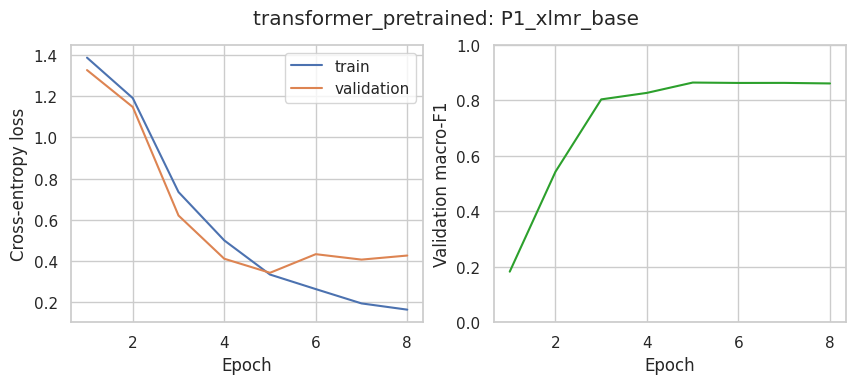

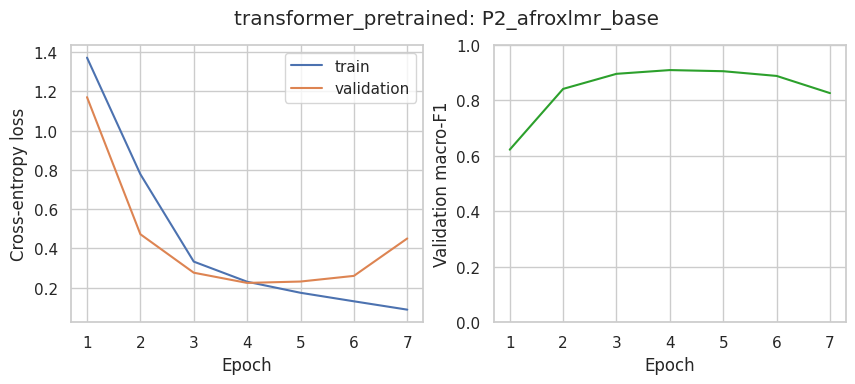

In [43]:
run("P1_xlmr_base", "xlmr_base", {}, "XLM-R base: no African-language adaptation")
run("P2_afroxlmr_base", "afroxlmr_base", {}, "AfroXLMR base: adapted to 17 African languages (not Lingala)")
if RUN_OPTIONAL_76L:
    run("P3_afroxlmr_base_76L", "afroxlmr_base_76L", {}, "AfroXLMR base 76L: adapted to 76 languages")
pd.DataFrame(results)

## Experiment group Q: truncation and class weights (best model from group P)

Best pretrained model: afroxlmr_base


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (559 > 512). Running this sequence through the model will result in indexin

Epoch 1: train loss 1.3726, validation loss 1.1822, macro-F1 0.5766
Epoch 2: train loss 0.7892, validation loss 0.4703, macro-F1 0.8667
Epoch 3: train loss 0.3305, validation loss 0.2730, macro-F1 0.9049
Epoch 4: train loss 0.2024, validation loss 0.2788, macro-F1 0.9064
Epoch 5: train loss 0.2211, validation loss 0.1984, macro-F1 0.9334
Epoch 6: train loss 0.1145, validation loss 0.2486, macro-F1 0.9158
Epoch 7: train loss 0.0716, validation loss 0.3416, macro-F1 0.8733
Epoch 8: train loss 0.0447, validation loss 0.3140, macro-F1 0.8827
Early stopping
Logged 'Q1_head_only' (validation) to transformer_pretrained.csv
{'experiment': 'Q1_head_only', 'model': 'afroxlmr_base', 'change': 'Keep only the first 510 tokens', 'macro_f1': 0.9334, 'weighted_f1': 0.9532, 'log_loss': 0.1984, 'best_epoch': 5}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (559 > 512). Running this sequence through the model will result in indexin

Epoch 1: train loss 1.2617, validation loss 1.0098, macro-F1 0.1825
Epoch 2: train loss 0.7043, validation loss 0.3416, macro-F1 0.7045
Epoch 3: train loss 0.2851, validation loss 0.2294, macro-F1 0.9007
Epoch 4: train loss 0.1778, validation loss 0.2382, macro-F1 0.9097
Epoch 5: train loss 0.1230, validation loss 0.2154, macro-F1 0.9184
Epoch 6: train loss 0.0858, validation loss 0.2224, macro-F1 0.8786
Epoch 7: train loss 0.0558, validation loss 0.3676, macro-F1 0.8706
Epoch 8: train loss 0.0438, validation loss 0.2265, macro-F1 0.9334
Epoch 9: train loss 0.0404, validation loss 0.2593, macro-F1 0.9334
Epoch 10: train loss 0.0370, validation loss 0.2593, macro-F1 0.9334
Logged 'Q2_no_class_weights' (validation) to transformer_pretrained.csv
{'experiment': 'Q2_no_class_weights', 'model': 'afroxlmr_base', 'change': 'Unweighted cross-entropy', 'macro_f1': 0.9334, 'weighted_f1': 0.9532, 'log_loss': 0.2265, 'best_epoch': 8}


,experiment,model,change,macro_f1,weighted_f1,log_loss,best_epoch
0,P1_xlmr_base,xlmr_base,XLM-R base: no African-language adaptation,0.8647,0.8900,0.3437,5
1,P2_afroxlmr_base,afroxlmr_base,AfroXLMR base: adapted to 17 African languages...,0.9097,0.9399,0.2241,4
2,Q1_head_only,afroxlmr_base,Keep only the first 510 tokens,0.9334,0.9532,0.1984,5
3,Q2_no_class_weights,afroxlmr_base,Unweighted cross-entropy,0.9334,0.9532,0.2265,8


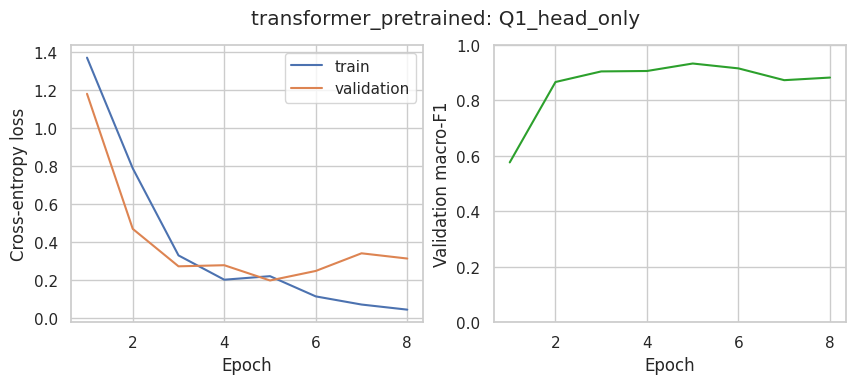

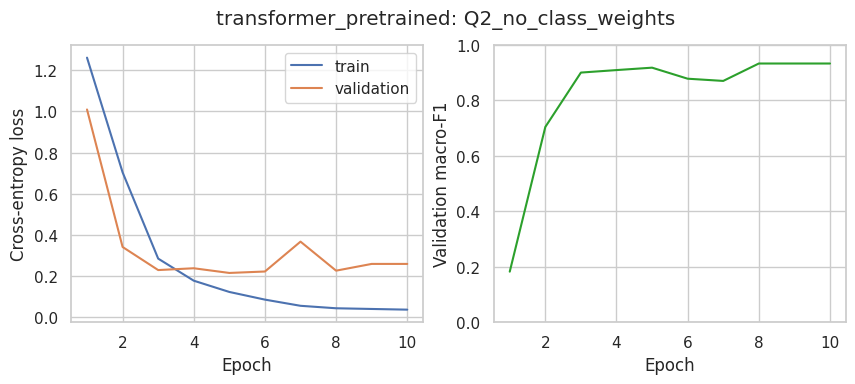

In [44]:
best_model = pd.DataFrame(results).sort_values(["macro_f1", "log_loss"], ascending=[False, True]).iloc[0]["model"]
print("Best pretrained model:", best_model)
run("Q1_head_only", best_model, {"strategy": "head"}, "Keep only the first 510 tokens")
run("Q2_no_class_weights", best_model, {"class_weight": False}, "Unweighted cross-entropy")
summary = pd.DataFrame(results)
summary.to_csv(config.RESULTS_DIRECTORY / "transformer_validation_summary.csv", index=False)
summary

## Final: best configuration with three seeds on the test set

Final: Q1_head_only afroxlmr_base {'strategy': 'head'}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (559 > 512). Running this sequence through the model will result in indexin

Epoch 1: train loss 1.3727, validation loss 1.2033, macro-F1 0.5591
Epoch 2: train loss 0.7870, validation loss 0.4676, macro-F1 0.8562
Epoch 3: train loss 0.3329, validation loss 0.2910, macro-F1 0.8962
Epoch 4: train loss 0.2050, validation loss 0.3267, macro-F1 0.8684
Epoch 5: train loss 0.1637, validation loss 0.2238, macro-F1 0.9007
Epoch 6: train loss 0.1040, validation loss 0.1762, macro-F1 0.9334
Epoch 7: train loss 0.0651, validation loss 0.2672, macro-F1 0.8733
Epoch 8: train loss 0.0450, validation loss 0.2987, macro-F1 0.8980
Epoch 9: train loss 0.0266, validation loss 0.2846, macro-F1 0.8952
Early stopping
seed 42: test macro-F1 0.9205


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (559 > 512). Running this sequence through the model will result in indexin

Epoch 1: train loss 1.3672, validation loss 1.2827, macro-F1 0.5497
Epoch 2: train loss 0.8044, validation loss 0.4052, macro-F1 0.9038
Epoch 3: train loss 0.3248, validation loss 0.2588, macro-F1 0.9028
Epoch 4: train loss 0.1974, validation loss 0.2293, macro-F1 0.9213
Epoch 5: train loss 0.1287, validation loss 0.2104, macro-F1 0.9245
Epoch 6: train loss 0.0867, validation loss 0.2125, macro-F1 0.9093
Epoch 7: train loss 0.0621, validation loss 0.2189, macro-F1 0.9170
Epoch 8: train loss 0.0604, validation loss 0.2428, macro-F1 0.9319
Epoch 9: train loss 0.0547, validation loss 0.2664, macro-F1 0.8787
Epoch 10: train loss 0.0391, validation loss 0.2645, macro-F1 0.9049
seed 7: test macro-F1 0.9183


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (559 > 512). Running this sequence through the model will result in indexin

Epoch 1: train loss 1.3740, validation loss 1.2464, macro-F1 0.3409
Epoch 2: train loss 0.9461, validation loss 0.4821, macro-F1 0.9158
Epoch 3: train loss 0.3813, validation loss 0.2453, macro-F1 0.8339
Epoch 4: train loss 0.2039, validation loss 0.2407, macro-F1 0.9249
Epoch 5: train loss 0.1216, validation loss 0.2533, macro-F1 0.8737
Epoch 6: train loss 0.0908, validation loss 0.2614, macro-F1 0.8906
Epoch 7: train loss 0.0593, validation loss 0.2944, macro-F1 0.9190
Early stopping
seed 2026: test macro-F1 0.8947
Logged 'FINAL_afroxlmr_base' (test) to transformer_pretrained.csv
Saved test probabilities to /content/lingala-news-classification/results/predictions/transformer.csv
Test macro-F1 0.9112 ± 0.0143; weighted-F1 0.9291
              precision    recall  f1-score   support

    politics      0.941     0.950     0.945       100
      health      0.949     0.949     0.949        39
      sports      1.000     1.000     1.000        19
    business      0.812     0.765     0.788

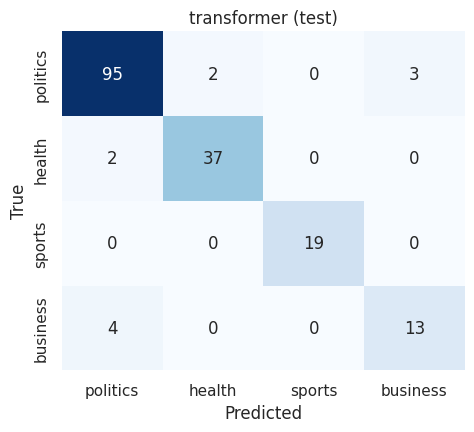

In [45]:
best_row = summary.sort_values(["macro_f1", "log_loss"], ascending=[False, True]).iloc[0]
final_changes = {"Q1_head_only": {"strategy": "head"}, "Q2_no_class_weights": {"class_weight": False}}.get(best_row["experiment"], {})
final_short_name = best_row["model"]
print("Final:", best_row["experiment"], final_short_name, final_changes)

seed_scores, first = [], None
for seed in config.FINAL_RUN_SEEDS:
    settings = {**BASE, **final_changes, "checkpoint": CHECKPOINTS[final_short_name], "seed": seed}
    model, tokenizer, history = transformer_training.run_experiment(settings, train, validation)
    probabilities = transformer_training.predict_probabilities(model, tokenizer, test, settings)
    seed_scores.append(evaluation.compute_scores(test_ids, probabilities))
    print(f"seed {seed}: test macro-F1 {seed_scores[-1]['macro_f1']:.4f}")
    if first is None:
        first = probabilities
        output = config.MODELS_DIRECTORY / "transformer_final"
        model.save_pretrained(output)
        tokenizer.save_pretrained(output)
        (output / "training_settings.json").write_text(json.dumps(settings, indent=2))
    del model
    transformer_training.free_memory()

summary_scores = evaluation.summarise_runs(seed_scores)
summary_scores["macro_f1_ci_low"], summary_scores["macro_f1_ci_high"] = evaluation.bootstrap_confidence_interval(test_ids, first.argmax(1))
log_experiment(MODEL_FAMILY, f"FINAL_{final_short_name}", "test", {**BASE, **final_changes, "checkpoint": CHECKPOINTS[final_short_name], "seeds": config.FINAL_RUN_SEEDS},
               summary_scores, "Mean/std over 3 seeds; CI and saved model from seed 42")
evaluation.save_test_predictions(first, "transformer")
print(f"Test macro-F1 {summary_scores['macro_f1']:.4f} ± {summary_scores['macro_f1_std']:.4f}; weighted-F1 {summary_scores['weighted_f1']:.4f}")
evaluation.print_classification_report(test_ids, first)
plots.plot_confusion_matrix(test_ids, first, "transformer", "test")
evaluation.save_misclassified_examples(test, test_ids, first, "transformer");

## Publish the model for the web app (Hugging Face Hub)
The fine-tuned model is about 1 GB, too big for GitHub. Upload it to your Hugging Face account; the Space then loads it by name.
Create a *write* token at https://huggingface.co/settings/tokens and paste it when asked.

In [46]:
import os
print("models folder:", os.listdir("/content/lingala-news-classification/models"))
print("predictions:", os.listdir("/content/lingala-news-classification/results/predictions"))
try:
    print("Validation results:"); display(summary)
except NameError:
    print("Part 6 experiments did not run")

models folder: ['word2vec_lingala_100d.model', 'tfidf_classifier.json', 'scratch_tokeniser', 'tfidf_classifier.joblib', 'transformer_final']
predictions: ['transformer.csv', 'word2vec_average.csv', 'tfidf_naive_bayes.csv', 'majority.csv', 'tfidf_best.csv', 'rnn.csv', 'transformer_scratch.csv']
Validation results:


,experiment,model,change,macro_f1,weighted_f1,log_loss,best_epoch
0,P1_xlmr_base,xlmr_base,XLM-R base: no African-language adaptation,0.8647,0.8900,0.3437,5
1,P2_afroxlmr_base,afroxlmr_base,AfroXLMR base: adapted to 17 African languages...,0.9097,0.9399,0.2241,4
2,Q1_head_only,afroxlmr_base,Keep only the first 510 tokens,0.9334,0.9532,0.1984,5
3,Q2_no_class_weights,afroxlmr_base,Unweighted cross-entropy,0.9334,0.9532,0.2265,8


In [47]:
HF_MODEL_REPO = "Heroine2/lingala-news-topic-classifier"
PUSH_TO_HUB = False

if PUSH_TO_HUB:
    from huggingface_hub import login
    from transformers import AutoModelForSequenceClassification
    login()
    model = AutoModelForSequenceClassification.from_pretrained(config.MODELS_DIRECTORY / "transformer_final")
    tokenizer = AutoTokenizer.from_pretrained(config.MODELS_DIRECTORY / "transformer_final")
    model.push_to_hub(HF_MODEL_REPO)
    tokenizer.push_to_hub(HF_MODEL_REPO)
    print("Uploaded to https://huggingface.co/" + HF_MODEL_REPO)

# Part 7: Results comparison and error analysis
This part rebuilds every number in the report from the experiment logs (`results/experiment_logs/`) and test-set probabilities (`results/predictions/`) written by Parts 2-6. Nothing is retrained here.

In [48]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config, data_loading, evaluation, plots
from src.experiment_log import load_all_experiments
from src.text_processing import tokenise

COMPARISON_DIRECTORY = config.RESULTS_DIRECTORY / "comparison"
COMPARISON_DIRECTORY.mkdir(parents=True, exist_ok=True)

train, validation, test = data_loading.load_all_splits()
test_ids = data_loading.labels_to_ids(test["category"])
logs = load_all_experiments()
predictions = evaluation.load_test_predictions()
print("Models with saved test predictions:", list(predictions))

Models with saved test predictions: ['majority', 'rnn', 'tfidf_best', 'tfidf_naive_bayes', 'transformer', 'transformer_scratch', 'word2vec_average']


## 1. All validation experiments

In [49]:
pd.set_option("display.max_colwidth", 60)
validation_table = logs[logs["split"].isin(["validation", "cv_train"])].pivot_table(
    index=["model_family", "experiment"], columns="split", values="macro_f1", aggfunc="last")
cv_std = logs[logs["split"] == "cv_train"].set_index(["model_family", "experiment"])["macro_f1_std"]
validation_table["cv_train_std"] = cv_std
notes = logs[logs["split"] == "validation"].drop_duplicates(["model_family", "experiment"], keep="last").set_index(["model_family", "experiment"])["notes"]
validation_table["what changed"] = notes
validation_table = validation_table.rename(columns={"validation": "validation macro-F1", "cv_train": "CV macro-F1 (train)", "cv_train_std": "CV std"})
validation_table.round(3).to_csv(COMPARISON_DIRECTORY / "all_validation_experiments.csv")
validation_table.round(3)

split                                                CV macro-F1 (train)  \
model_family           experiment                                          
bag_of_words           A1_majority                                 0.183   
                       A2_nb_alpha1                                0.216   
                       A3_nb_alpha0.1                              0.684   
                       A4_complement_nb                            0.746   
                       A5_logreg                                   0.760   
                       A6_logreg_balanced                          0.840   
                       A7_svm_balanced                             0.854   
                       B1_word_1-2grams                            0.789   
                       B2_char_2-5                                 0.852   
                       B3_char_3-6                                 0.848   
                       B4_word+char                                0.845   
                       B5_svm_word+char                            0.855   
                       C1_headline_only                            0.710   
                       C2_text_only                                0.851   
                       C3_strip_accents                            0.858   
                       D_C=0.1                                     0.843   
                       D_C=10                                      0.861   
rnn                    R1_bilstm_random_embeddings                   NaN   
                       R2_bilstm_word2vec_finetuned                  NaN   
                       R3_bilstm_word2vec_frozen                     NaN   
                       R4_bilstm_last_state                          NaN   
                       R5_bigru_attention                            NaN   
                       R6_bilstm_no_class_weights                    NaN   
transformer_pretrained P1_xlmr_base                                  NaN   
                       P2_afroxlmr_base                              NaN   
                       Q1_head_only                                  NaN   
                       Q2_no_class_weights                           NaN   
transformer_scratch    T1_2layers_128d                               NaN   
                       T2_4layers_256d                               NaN   
                       T3_2layers_512tokens                          NaN   
word2vec               W1_skipgram_100d                              NaN   
                       W2_cbow_100d                                  NaN   
                       W3_skipgram_300d                              NaN   
                       W4_skipgram_window10                          NaN   
                       W5_skipgram_strip_accents                     NaN   

split                                                validation macro-F1  \
model_family           experiment                                          
bag_of_words           A1_majority                                 0.182   
                       A2_nb_alpha1                                0.233   
                       A3_nb_alpha0.1                              0.753   
                       A4_complement_nb                            0.828   
                       A5_logreg                                   0.787   
                       A6_logreg_balanced                          0.902   
                       A7_svm_balanced                             0.902   
                       B1_word_1-2grams                            0.866   
                       B2_char_2-5                                 0.868   
                       B3_char_3-6                                 0.868   
                       B4_word+char                                0.881   
                       B5_svm_word+char                            0.881   
                       C1_headline_only                            0.762   
                       C2_text_only            

## 2. Final test-set results
Neural models: mean ± standard deviation over 3 seeds. Bag-of-words models are deterministic, so they have one score
(their variability is shown by the cross-validation std above). The 95% interval is a bootstrap over the 175 test articles.

In [50]:
DISPLAY_NAMES = {
    "majority": "Majority class",
    "tfidf_naive_bayes": "TF-IDF + Naive Bayes",
    "tfidf_best": "TF-IDF (word+char) + linear SVM",
    "word2vec_average": "Averaged Word2Vec + LogReg",
    "rnn": "BiLSTM + attention (Word2Vec init)",
    "transformer_scratch": "Transformer from scratch",
    "transformer": "Fine-tuned pretrained Transformer",
}
FAMILY_OF = {"majority": "bag_of_words", "tfidf_naive_bayes": "bag_of_words", "tfidf_best": "bag_of_words",
             "word2vec_average": "word2vec", "rnn": "rnn", "transformer_scratch": "transformer_scratch",
             "transformer": "transformer_pretrained"}

final_logs = logs[(logs["split"] == "test") & logs["experiment"].str.startswith("FINAL")]
rows = []
for name in DISPLAY_NAMES:
    if name not in predictions:
        continue
    family_rows = final_logs[final_logs["model_family"] == FAMILY_OF[name]]
    if FAMILY_OF[name] == "bag_of_words":
        family_rows = family_rows[family_rows["experiment"] == f"FINAL_{name}"]
    row = family_rows.iloc[-1]
    std = row.get("macro_f1_std")
    rows.append({
        "model": DISPLAY_NAMES[name],
        "macro-F1": row["macro_f1"],
        "± std (seeds)": None if pd.isna(std) else std,
        "95% CI": f"{row['macro_f1_ci_low']:.3f}-{row['macro_f1_ci_high']:.3f}",
        "weighted-F1": row["weighted_f1"],
        "accuracy": row["accuracy"],
        "macro precision": row["macro_precision"],
        "macro recall": row["macro_recall"],
        **{f"F1 {label}": row[f"f1_{label}"] for label in config.LABELS},
        "key": name,
    })
final_table = pd.DataFrame(rows)
final_table.drop(columns="key").round(3).to_csv(COMPARISON_DIRECTORY / "final_test_results.csv", index=False)
final_table.drop(columns="key").round(3)

,model,macro-F1,± std (seeds),95% CI,weighted-F1,accuracy,macro precision,macro recall,F1 politics,F1 health,F1 sports,F1 business
0,Majority class,0.182,NaN,0.165-0.196,0.416,0.571,0.143,0.250,0.727,0.000,0.000,0.000
1,TF-IDF + Naive Bayes,0.673,NaN,0.609-0.738,0.773,0.811,0.929,0.653,0.857,0.750,0.973,0.111
2,TF-IDF (word+char) + linear SVM,0.822,NaN,0.747-0.884,0.852,0.857,0.877,0.786,0.884,0.812,0.973,0.621
3,Averaged Word2Vec + LogReg,0.860,NaN,0.797-0.909,0.875,0.874,0.870,0.865,0.898,0.824,1.000,0.718
4,BiLSTM + attention (Word2Vec init),0.859,0.026,0.822-0.935,0.888,0.893,0.913,0.831,0.916,0.867,0.991,0.661
5,Transformer from scratch,0.824,0.041,0.703-0.853,0.876,0.880,0.858,0.801,0.916,0.880,0.937,0.563
6,Fine-tuned pretrained Transformer,0.911,0.014,0.866-0.963,0.929,0.930,0.917,0.908,0.942,0.932,0.982,0.788


### Context: published MasakhaNEWS results for Lingala
Adelani et al. (2023, Table 3) report **weighted-F1** on the same test set (headline + text): MLP 84.3, Naive Bayes 82.8,
XGBoost 74.8, AfriBERTa 87.0, XLM-R-base 87.9, AfroXLMR-base 93.0, XLM-R-large 91.8, AfroXLMR-large 93.7.
Compare these with our weighted-F1 column, not with macro-F1.

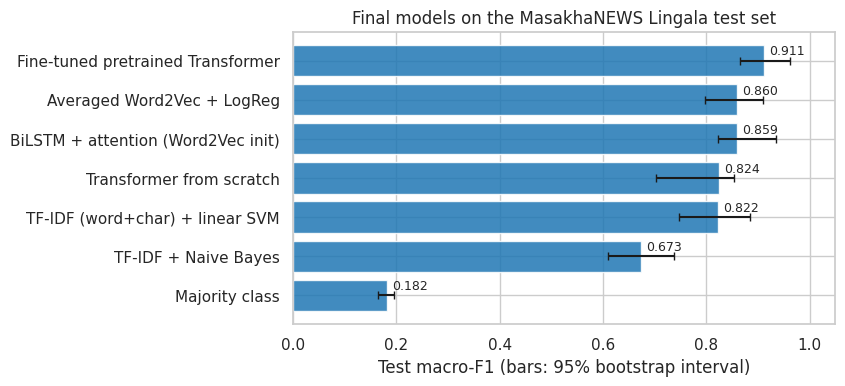

In [51]:
figure, axis = plt.subplots(figsize=(7, 3.8))
ordered = final_table.sort_values("macro-F1")
low = ordered["macro-F1"] - ordered["95% CI"].str.split("-").str[0].astype(float)
high = ordered["95% CI"].str.split("-").str[1].astype(float) - ordered["macro-F1"]
axis.barh(ordered["model"], ordered["macro-F1"], xerr=[low.clip(lower=0), high.clip(lower=0)], color="tab:blue", alpha=0.85, capsize=3)
for y, value in enumerate(ordered["macro-F1"]):
    axis.text(value + 0.01, y + 0.15, f"{value:.3f}", fontsize=9)
axis.set_xlim(0, 1.05)
axis.set_xlabel("Test macro-F1 (bars: 95% bootstrap interval)")
axis.set_title("Final models on the MasakhaNEWS Lingala test set")
figure.savefig(COMPARISON_DIRECTORY / "test_macro_f1.png", dpi=150, bbox_inches="tight")

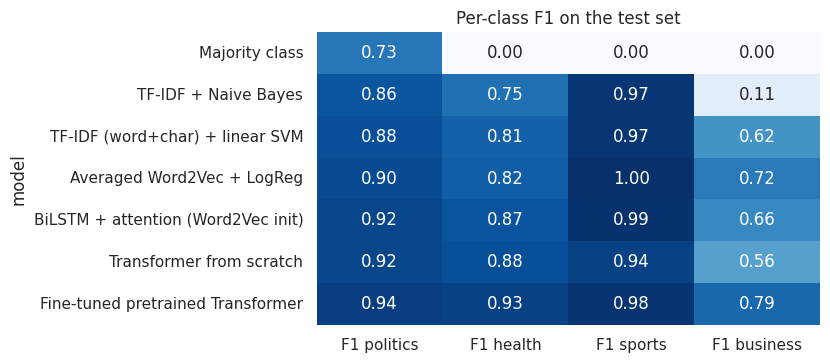

In [52]:
per_class = final_table.set_index("model")[[f"F1 {label}" for label in config.LABELS]]
figure, axis = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(per_class, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axis, cbar=False)
axis.set_title("Per-class F1 on the test set")
figure.savefig(COMPARISON_DIRECTORY / "per_class_f1.png", dpi=150, bbox_inches="tight")

## 3. Are the differences real? Paired bootstrap test
For each model we resample the test articles 2,000 times and count how often it does **not** beat the TF-IDF + SVM baseline
on macro-F1. A value below 0.05 means the improvement (or, if the model is worse, the gap is reversed) is unlikely to be luck.

In [53]:
baseline = predictions["tfidf_best"].argmax(1)
rows = []
for name, probabilities in predictions.items():
    if name == "tfidf_best":
        continue
    model_predictions = probabilities.argmax(1)
    rows.append({
        "model": DISPLAY_NAMES.get(name, name),
        "share of resamples where it is NOT better than TF-IDF+SVM": evaluation.paired_bootstrap_test(test_ids, baseline, model_predictions),
        "articles it gets right that TF-IDF+SVM gets wrong": int(((model_predictions == test_ids) & (baseline != test_ids)).sum()),
        "articles TF-IDF+SVM gets right that it gets wrong": int(((model_predictions != test_ids) & (baseline == test_ids)).sum()),
    })
significance = pd.DataFrame(rows)
significance.to_csv(COMPARISON_DIRECTORY / "paired_bootstrap_vs_tfidf.csv", index=False)
significance

,model,share of resamples where it is NOT better than TF-IDF+SVM,articles it gets right that TF-IDF+SVM gets wrong,articles TF-IDF+SVM gets right that it gets wrong
0,Majority class,1.000,5,55
1,BiLSTM + attention (Word2Vec init),0.029,16,7
2,TF-IDF + Naive Bayes,1.000,4,12
3,Fine-tuned pretrained Transformer,0.002,19,5
4,Transformer from scratch,0.824,10,10
5,Averaged Word2Vec + LogReg,0.103,8,5


## 4. Error analysis of the deployed model
We analyse the fine-tuned Transformer if its predictions are available, otherwise the TF-IDF + SVM model.

Analysing: Fine-tuned pretrained Transformer
11 errors out of 175 test articles


,,errors
true_label,predicted_label,
business,politics,4
politics,business,3
health,politics,2
politics,health,2


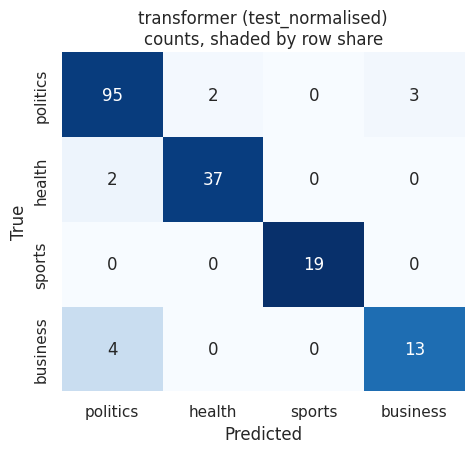

In [54]:
ANALYSED = "transformer" if "transformer" in predictions else "tfidf_best"
probabilities = predictions[ANALYSED]
print("Analysing:", DISPLAY_NAMES[ANALYSED])
table = evaluation.build_prediction_table(test, test_ids, probabilities)
plots.plot_confusion_matrix(test_ids, probabilities, ANALYSED, "test_normalised", normalise=True)
print(f"{(~table['correct']).sum()} errors out of {len(table)} test articles")
errors = table[~table["correct"]]
errors.groupby(["true_label", "predicted_label"]).size().sort_values(ascending=False).to_frame("errors")

### 4.1 Do errors depend on length, unseen words, French or confidence?

In [55]:
train_vocabulary = {w for text in train["content"] for w in tokenise(text)}
french_pattern = re.compile(r"[éèêëàâçôûùîï]|(?:tion|ment|ique|eur|aire)s?$")

def unseen_share(text):
    tokens = tokenise(text)
    return np.mean([t not in train_vocabulary for t in tokens])

def french_share(text):
    tokens = tokenise(text)
    return np.mean([bool(french_pattern.search(t)) for t in tokens])

table["unseen_word_share"] = table["content"].apply(unseen_share)
table["french_like_share"] = table["content"].apply(french_share)
factors = table.groupby("correct")[["words", "unseen_word_share", "french_like_share", "confidence"]].mean().round(3)
factors.index = factors.index.map({True: "correct", False: "wrong"})
display(factors)

bins = pd.cut(table["confidence"], [0, 0.5, 0.7, 0.9, 1.0])
reliability = table.groupby(bins, observed=True)["correct"].agg(["mean", "size"]).rename(columns={"mean": "accuracy", "size": "articles"})
reliability.round(3)

,words,unseen_word_share,french_like_share,confidence
correct,,,,
wrong,201.909,0.051,0.067,0.884
correct,180.445,0.068,0.041,0.976


,accuracy,articles
confidence,,
"(0.5, 0.7]",0.600,5
"(0.7, 0.9]",0.833,6
"(0.9, 1.0]",0.951,164


**Reading this table.** If wrong predictions have clearly lower confidence, the model "knows when it does not know", which the
web app uses to warn the user. If wrong articles are not longer and do not have more unseen words, the errors are not caused by
truncation or vocabulary gaps but by the **content**: articles that genuinely mix topics.

### 4.2 Articles that every model gets wrong

In [56]:
real_models = [n for n in predictions if n != "majority"]
wrong_by = pd.DataFrame({DISPLAY_NAMES[n]: predictions[n].argmax(1) != test_ids for n in real_models})
table["models_wrong"] = wrong_by.sum(axis=1).to_numpy()
hard = table[table["models_wrong"] == len(real_models)].copy()
for n in real_models:
    hard[n] = [config.LABELS[i] for i in predictions[n].argmax(1)[hard.index]]
print(f"{len(hard)} test articles are misclassified by all {len(real_models)} non-trivial models")
hard[["headline", "true_label"] + real_models].to_csv(COMPARISON_DIRECTORY / "hard_examples.csv", index=False)
hard[["headline", "true_label"] + real_models]

3 test articles are misclassified by all 6 non-trivial models


,headline,true_label,rnn,tfidf_best,tfidf_naive_bayes,transformer,transformer_scratch,word2vec_average
10,Basali ya société canadienne Banro bakangami na basimba ...,business,politics,politics,politics,politics,politics,politics
14,Ouganda na RDC batie manzaka na boyokani mpo na botongam...,business,politics,politics,politics,politics,politics,politics
41,Parlement endimi kobakisa mikolo na état d'urgence sanit...,health,business,politics,politics,politics,politics,politics


These are the best candidates for **label ambiguity**: when models with completely different inductive biases (word counts,
character n-grams, sequence models, pretrained Transformers) all agree on another topic, the article usually discusses two topics
(for example the provincial assembly cancelling a session because of COVID-19, labelled *health*), and the annotators' choice is
one of two defensible answers. This is consistent with the moderate annotator agreement reported for Lingala (Fleiss' kappa 0.56).

### 4.3 Most confident errors and most confident successes

In [57]:
columns = ["headline", "true_label", "predicted_label", "confidence", "words"]
print("Most confident errors:")
display(errors.sort_values("confidence", ascending=False)[columns].head(8))
print("Most confident correct prediction per class:")
display(table[table["correct"]].sort_values("confidence", ascending=False).groupby("true_label").head(2)[columns])
errors.sort_values("confidence", ascending=False).to_csv(COMPARISON_DIRECTORY / f"errors_{ANALYSED}.csv", index=False)

Most confident errors:


,headline,true_label,predicted_label,confidence,words
3,Sassou asengi lisungi mpo na Fonds bleu ya bassain ya Co...,business,politics,0.9887,174
14,Ouganda na RDC batie manzaka na boyokani mpo na botongam...,business,politics,0.9885,299
111,"Pompeo akebisi mpo na ""bilaka ya bampa"" ya Chine na Afrique",politics,business,0.9883,232
10,Basali ya société canadienne Banro bakangami na basimba ...,business,politics,0.9805,154
48,Assemblée nationale endimi kobakisi mikolo na état d'urg...,health,politics,0.9799,220
41,Parlement endimi kobakisa mikolo na état d'urgence sanit...,health,politics,0.9673,73
88,"Christophe Moukouéké, kalaka mokonzi ya UPADS akufi na m...",politics,health,0.9484,123
77,Matata Ponyo asengi IGF kolandela bokweyisami ya Bukanga...,politics,business,0.9336,322


Most confident correct prediction per class:


,headline,true_label,predicted_label,confidence,words
167,Katumbi azwi palata ya mokambi ya malamu koleka na CAF A...,sports,sports,0.9957,217
161,Tunisie na Angola bakaboli 1-1,sports,sports,0.9957,97
45,Rwanda ekebisi bato kosala mobembo na RDC mpo na Ebola n...,health,health,0.9944,234
32,Onu etieyi mokambi ya bitumba na Ebola na RDC,health,health,0.9944,131
15,FMI elobi nkita ekiti moke na RDC,business,business,0.9927,190
4,FMI etindi limpinga na Kinshasa kolandela makambo ya kan...,business,business,0.9926,233
69,"Ramazani Shadary na Likasi : ""Kabila nde nkolo l'Etat""",politics,politics,0.9916,200
86,Bemba ayebisi Tshisekedi akopesa ye maboko,politics,politics,0.9912,237


In [58]:
import shutil
from getpass import getpass
from huggingface_hub import login
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from google.colab import files

archive = shutil.make_archive("results", "zip", root_dir=".", base_dir="results")
files.download(archive)

login(token=getpass("Paste your Hugging Face WRITE token (hf_...): "))
final_directory = config.MODELS_DIRECTORY / "transformer_final"
model = AutoModelForSequenceClassification.from_pretrained(str(final_directory))
tokenizer = AutoTokenizer.from_pretrained(str(final_directory))
model.push_to_hub("Heroine2/lingala-news-topic-classifier")
tokenizer.push_to_hub("Heroine2/lingala-news-topic-classifier")
print("Uploaded to https://huggingface.co/Heroine2/lingala-news-topic-classifier")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Paste your Hugging Face WRITE token (hf_...): ··········


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpj5eo8mvb/tokenizer.json:   1%|1         |  249kB / 17.1MB            

Validating                    :           |   0%            

Uploaded to https://huggingface.co/Heroine2/lingala-news-topic-classifier


## Download the results
The zip holds the `results/` folder (experiment logs, predictions, figures, comparison tables). Unzip it into your repository and commit it. Also save this notebook with its outputs: **File → Download → Download .ipynb**.